# Conditional VAE Transformer (TCVAE): Generating molecules with desired properties

**CHEM 584: Introduction to Machine Learning and Quantum Computing**

Prof. Victor S. Batista

*An earlier version of this assignment was designed by Dr. Haote Li.*

**Version 1.0 · November 2026 · runs on Google Colab with a GPU runtime (T4 is enough).**
**How to cite:** V. S. Batista, *Conditional VAE Transformer (TCVAE): generating molecules with desired properties*, CHEM 584 tutorial notebook, version 1.0 (2026).
**License:** text CC BY 4.0, code MIT.

## 1. Introduction

In drug discovery we rarely want *any* new molecule: we want molecules with **specific properties**, for example a certain solubility, a high drug-likeness, or an easy synthesis. The companion tutorial *VAE Transformer: De novo generation of molecules* showed how to sample new molecules from a generative model, but gave no handle on their properties: a standard VAE models the distribution of molecules $p(x)$, and sampling from it returns molecules with whatever properties the training set happened to have.

A **conditional** model describes instead the distribution of molecules *given* a set of properties $c$, which we write $p(x\,|\,c)$. If we fix $c$ and sample at random, we should obtain many different molecules that all have properties close to $c$. In this tutorial we build such a model, a **conditional VAE with a Transformer architecture (TCVAE)**, and, more importantly, we **test whether the control really works**.

### What you will learn
After working through this notebook you will be able to:
1. turn continuous molecular properties (LogP, QED, SAS) into **discrete condition tokens**, and append them to the tokenised SMILES strings;
2. explain how the condition reaches the decoder (Figure 1), and what is new compared with the unconditional VAE;
3. sample molecules for a requested property value and **measure with an independent calculation** (RDKit) whether the request was honoured;
4. design a fair test of controllability: **requested versus achieved** properties over many classes, with attention to *where the training data are sparse* and to whether the *combination* of requested properties is realistic;
5. **edit** a molecule: keep its latent vector and change only the requested property.

### What you need
Basic Python and PyTorch. The notebook is self-contained, but the companion VAE tutorial explains the Transformer and MMD ingredients in more detail (Section 4 gives a summary).

### Roadmap

| Section | Content | Time on a T4 |
|---|---|---|
| 1 | Introduction | |
| 2 | Setup: libraries, seeds, 3D viewer | |
| 3 | Data: properties to condition tokens, tokenisation, batches | |
| 4 | The model: what is new in the conditional Transformer | |
| 5 | Training (optional) and loading the pre-trained model | training: about 5 min per epoch (skipped by default) |
| 6 | Evaluation without conditions: latent space and sampling | canonicalising ZINC takes about 1.5 minutes |
| 7 | Conditional generation: examples, editing, systematic tests | |
| 8 | Check your understanding and exercises | |

**How to run.** Select a GPU runtime (**Runtime → Change runtime type → GPU**), then run the cells from top to bottom. The ZINC data are downloaded automatically. The pre-trained model file has to be provided by you (Section 3.1). Cells whose code is hidden (form cells) are plumbing; click *Show code* if you are curious.

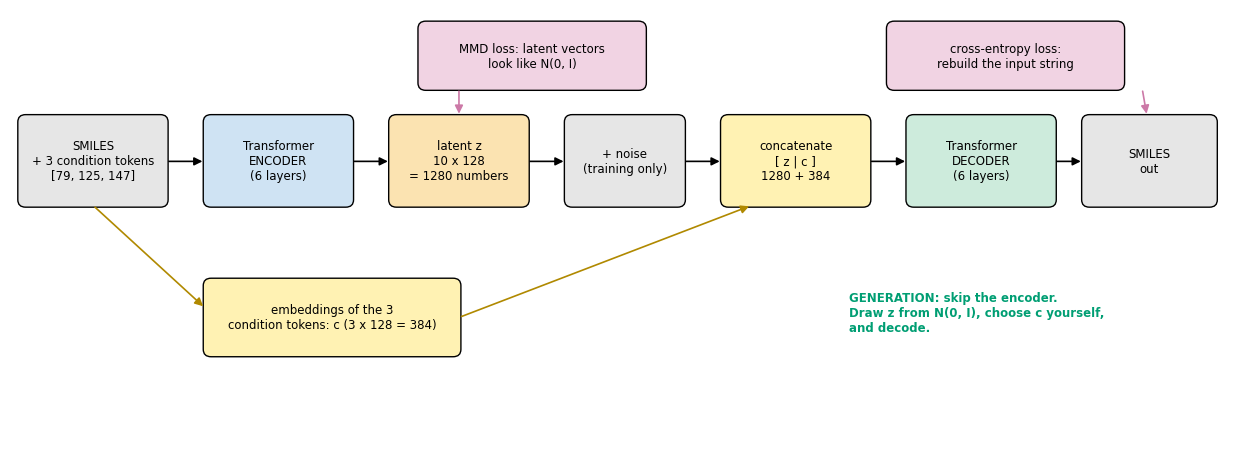

In [1]:
#@title Figure 1: the conditional model at a glance { display-mode: "form" }
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="k", lw=1))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=8.5)

def arrow(ax, p, q, color="k", style="-|>", ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=12, lw=1.2, color=color, linestyle=ls))

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.set_xlim(0, 12.5); ax.set_ylim(0, 4.6); ax.axis("off")
blue, green, orange, pink, gray, yellow = "#cfe3f3", "#cdebdc", "#fbe3b1", "#f1d3e3", "#e6e6e6", "#fff2b3"

# main row: training / reconstruction path
box(ax, 0.1, 2.5, 1.5, 0.95, "SMILES\n+ 3 condition tokens\n[79, 125, 147]", gray)
box(ax, 2.0, 2.5, 1.5, 0.95, "Transformer\nENCODER\n(6 layers)", blue)
box(ax, 3.9, 2.5, 1.4, 0.95, "latent z\n10 x 128\n= 1280 numbers", orange)
box(ax, 5.7, 2.5, 1.2, 0.95, "+ noise\n(training only)", gray)
box(ax, 7.3, 2.5, 1.5, 0.95, "concatenate\n[ z | c ]\n1280 + 384", yellow)
box(ax, 9.2, 2.5, 1.5, 0.95, "Transformer\nDECODER\n(6 layers)", green)
box(ax, 11.0, 2.5, 1.35, 0.95, "SMILES\nout", gray)
for x0, x1 in [(1.6, 2.0), (3.5, 3.9), (5.3, 5.7), (6.9, 7.3), (8.8, 9.2), (10.7, 11.0)]:
    arrow(ax, (x0, 2.97), (x1, 2.97))
# condition path: embeddings of the 3 condition tokens go straight to the concatenation
box(ax, 2.0, 0.9, 2.6, 0.8, "embeddings of the 3\ncondition tokens: c (3 x 128 = 384)", yellow)
arrow(ax, (0.85, 2.5), (2.0, 1.4), color="#b08900")
arrow(ax, (4.6, 1.3), (7.6, 2.5), color="#b08900")
# losses
box(ax, 4.2, 3.75, 2.3, 0.7, "MMD loss: latent vectors\nlook like N(0, I)", pink)
arrow(ax, (4.6, 3.75), (4.6, 3.45), color="#CC79A7")
box(ax, 9.0, 3.75, 2.4, 0.7, "cross-entropy loss:\nrebuild the input string", pink)
arrow(ax, (11.6, 3.75), (11.65, 3.45), color="#CC79A7")
# generation
ax.text(8.6, 1.35, "GENERATION: skip the encoder.\nDraw z from N(0, I), choose c yourself,\nand decode.", ha="left", va="center", fontsize=8.5, color="#009E73", weight="bold")
plt.tight_layout(); plt.show()

**Figure 1.** The model has the same structure as the unconditional VAE of the companion tutorial, with one addition (yellow): the three **condition tokens** (the classes of LogP, QED and SAS) are embedded, and their embeddings $c$ (3 × 128 = 384 numbers) are **concatenated with the latent vector** before the decoder. During training the decoder therefore always receives the properties of the molecule it must rebuild. After training we generate by drawing the latent vector $z$ from $N(0,I)$ and choosing $c$ ourselves: that is the handle on the properties.

## 2. Setup

### 2.1 Install libraries
Colab already provides PyTorch, NumPy, pandas, scikit-learn and Matplotlib. We only need to add two packages: **RDKit**, an open-source cheminformatics toolkit that we use to check generated strings, to compute LogP and QED independently of the model, and to build 3D structures; and **py3Dmol**, which displays molecules as interactive 3D views.

In [2]:
#@title Install RDKit and py3Dmol { display-mode: "form" }
%pip install -q rdkit
%pip install -q py3Dmol

### 2.2 Imports, seeds and helper functions
The next cell imports everything we need, fixes the **random seeds** (so that sampling is reproducible), selects the **device** (GPU if available), prints the versions of the main packages, and defines two tests for generated SMILES strings:

* `is_SMILE(name)`: can RDKit *parse* the string? (a grammar check only, `sanitize=False`)
* `is_valid_molecule(name)`: does it also pass RDKit's *chemical sanitisation* (valence rules, aromaticity, ...)? This is the stricter and more meaningful test.

In [3]:
import os, sys, io, math, random, pickle, hashlib, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import rdkit
import py3Dmol
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import AllChem, Draw, QED, Crippen, rdFingerprintGenerator
from rdkit.Chem.Draw import IPythonConsole          # makes Mol objects render as pictures
RDLogger.DisableLog('rdApp.*')                      # RDKit prints many harmless error messages; silence them
try:
  IPythonConsole.drawOptions.bondLineWidth = 1.8
except AttributeError:
  pass

# --- reproducibility and a consistent figure style ------------------------------------------
SEED = 0
def set_seed(seed=SEED):
  random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")  # colour-blind safe
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

IN_COLAB = "google.colab" in sys.modules
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | RDKit {rdkit.__version__} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))
if device.type == 'cpu':
  print("WARNING: no GPU found. Use Runtime > Change runtime type > GPU; generation and training are very slow on CPU.")

def is_SMILE(name):
  # Input a SMILES string and return whether RDKit can PARSE it (grammar only, no chemistry checks)
  return(Chem.MolFromSmiles(name, sanitize=False) is not None)

def is_valid_molecule(name):
  # Stricter test: the string must parse AND pass RDKit's chemical sanitisation (valences, aromaticity, ...)
  return(len(name) > 0 and Chem.MolFromSmiles(name) is not None)

python 3.13.16 | torch 2.14.1+cu130 | RDKit 2026.09.2 | numpy 2.4.6 | pandas 2.2.3
device: cuda (Tesla T4)


### 2.3 Looking at molecules in 3D
Molecules are three-dimensional objects, so we display them with **py3Dmol**: interactive 3D views that you can **rotate (drag), zoom (scroll) and pan**. A SMILES string only describes which atoms are bonded to which, not where they sit in space, so the helper below first builds a plausible 3D structure with RDKit (hydrogens added, one conformer generated with the ETKDG method, then a quick force-field cleanup; hydrogens are hidden in the picture for clarity). Keep in mind that this is *one* plausible conformer, not a computed minimum-energy structure.

py3Dmol views are small JavaScript applications: they need a live Colab session and do not appear in static copies of the notebook (for example on GitHub or in a PDF). Set `MOL_VIEW = "2d"` in the cell below to get ordinary pictures instead.

In [4]:
#@title Helpers to view molecules { display-mode: "form" }
MOL_VIEW = "3d" #@param ["3d", "2d"]

def mol_to_3d(mol_or_smiles, seed=0):
  """RDKit molecule with 3D coordinates (hydrogens are hidden but the coordinates are kept); None if it fails."""
  mol = Chem.MolFromSmiles(mol_or_smiles) if isinstance(mol_or_smiles, str) else mol_or_smiles
  if mol is None:
    return None
  mh = Chem.AddHs(mol)                                    # hydrogens are needed for a sensible 3D geometry
  params = AllChem.ETKDGv3(); params.randomSeed = seed
  if AllChem.EmbedMolecule(mh, params) != 0:              # distance-geometry embedding
    params.useRandomCoords = True
    if AllChem.EmbedMolecule(mh, params) != 0:
      return None
  try:
    AllChem.MMFFOptimizeMolecule(mh, maxIters=500)        # quick force-field cleanup
  except Exception:
    pass
  return Chem.RemoveHs(mh)

def show_grid(mols, legends=None, ncols=4, cell=(260, 230)):
  """Show molecules (SMILES strings, RDKit molecules or None) in a grid, with an optional label for each."""
  n = len(mols); nrows = int(math.ceil(n / ncols))
  legends = list(legends) if legends is not None else [""] * n
  if MOL_VIEW == "2d":                                    # static pictures
    ms = []
    for m in mols:
      mm = Chem.MolFromSmiles(m) if isinstance(m, str) else m
      ms.append(mm if mm is not None else Chem.Mol())
    return Draw.MolsToGridImage(ms, molsPerRow=ncols, subImgSize=cell, legends=legends)
  view = py3Dmol.view(width=cell[0] * ncols, height=cell[1] * nrows, viewergrid=(nrows, ncols))
  for k, (m, text) in enumerate(zip(mols, legends)):
    r, c = divmod(k, ncols)
    m3 = mol_to_3d(m) if m is not None else None
    if m3 is not None:
      view.addModel(Chem.MolToMolBlock(m3), "mol", viewer=(r, c))
      view.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.25}}, viewer=(r, c))   # ball-and-stick
      view.zoomTo(viewer=(r, c))
    else:                                                 # nothing to draw: say why in the label
      text = (text + (" (3D structure could not be built)" if m is not None else "")).strip() or "no structure"
    if text:
      view.addLabel(text, {"fontSize": 11, "fontColor": "black", "backgroundColor": "white",
                           "backgroundOpacity": 0.7, "useScreen": True, "alignment": "topLeft"}, viewer=(r, c))
  return view.show()

def show_mol(mol_or_smiles, title=None, size=(380, 300)):
  """Show a single molecule."""
  return show_grid([mol_or_smiles], [title] if title else None, ncols=1, cell=size)

show_mol("CC(=O)Oc1ccccc1C(=O)O", title="Aspirin (a test of the viewer)")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 3. Data

### 3.1 Providing the data files
Two files are needed:

* **`250k_rndm_zinc_drugs_clean_3.csv`**: 250,000 drug-like molecules from the ZINC library (as distributed in the `chemical_vae` repository of the Aspuru-Guzik group), with their SMILES string and three computed properties: the octanol-water partition coefficient **LogP**, the quantitative estimate of drug-likeness **QED**, and the synthetic-accessibility score **SAS**. By default it is **downloaded automatically**.
* **The pre-trained model.** Choose `CVAE_transformer_model.pckl` (a pickle of the whole model, the format of the original tutorial) or `CVAE_transformer_state_dict.pt` (the weights only: **safer**, and the format we recommend; see Section 5). The model is **not downloadable automatically**: choose `upload` (file picker) or `google_drive`, or `none` to continue with an untrained model (only useful if you plan to train it yourself).

> ⚠️ **Security note.** A Python *pickle* can execute arbitrary code when loaded. Only load a `.pckl` file that you received from a source you trust. A `state_dict` file contains only numbers and is loaded with `weights_only=True`.

In [5]:
#@title Provide the data files { display-mode: "form" }
csv_source = "download" #@param ["download", "upload", "google_drive"]
model_source = "upload" #@param ["upload", "google_drive", "none (random weights)"]
model_file = "CVAE_transformer_model.pckl" #@param ["CVAE_transformer_model.pckl", "CVAE_transformer_state_dict.pt"]
drive_folder = "/content/drive/MyDrive/TCVAE_Tutorial" #@param {type:"string"}

CSV_NAME = "250k_rndm_zinc_drugs_clean_3.csv"
CSV_URL = ("https://raw.githubusercontent.com/aspuru-guzik-group/chemical_vae/master/"
           "models/zinc_properties/250k_rndm_zinc_drugs_clean_3.csv")
MODEL_NAME = model_file

def _upload(name):
  if not IN_COLAB:
    raise RuntimeError(f"Not running in Colab: place {name} next to the notebook and re-run this cell.")
  from google.colab import files
  print(f"Select {name} in the dialog below ...")
  uploaded = files.upload()
  if not uploaded:
    raise FileNotFoundError("No file was uploaded.")
  got = next(iter(uploaded))
  if got != name:                       # Colab appends "(1)" etc. to repeated uploads
    os.replace(got, name)
  return name

def _from_drive(name):
  from google.colab import drive
  drive.mount('/content/drive')
  path = os.path.join(drive_folder, name)
  if not os.path.exists(path):
    raise FileNotFoundError(f"Not found: {path}\nCheck 'drive_folder' above.")
  return path

if os.path.exists(CSV_NAME):
  CSV_PATH = CSV_NAME
elif csv_source == "download":
  print("Downloading the ZINC data set (about 22 MB) ...")
  urllib.request.urlretrieve(CSV_URL, CSV_NAME)
  CSV_PATH = CSV_NAME
elif csv_source == "upload":
  CSV_PATH = _upload(CSV_NAME)
else:
  CSV_PATH = _from_drive(CSV_NAME)

if os.path.exists(MODEL_NAME):
  MODEL_PATH = MODEL_NAME
elif model_source == "upload":
  MODEL_PATH = _upload(MODEL_NAME)
elif model_source == "google_drive":
  MODEL_PATH = _from_drive(MODEL_NAME)
else:
  MODEL_PATH = None

print("ZINC csv :", CSV_PATH, f"({os.path.getsize(CSV_PATH)/1e6:.1f} MB)")
print("model    :", MODEL_PATH if MODEL_PATH else "none (untrained model will be used)")

Select CVAE_transformer_model.pckl in the dialog below ...


Saving CVAE_transformer_model.pckl to CVAE_transformer_model.pckl
ZINC csv : 250k_rndm_zinc_drugs_clean_3.csv (22.6 MB)
model    : CVAE_transformer_model.pckl


### 3.2 From properties to condition tokens
The model reads discrete tokens, so continuous property values must be **discretised**. For each property we cut the range between its smallest and largest value in the data set into **50 equal-width classes** (numbered 0 to 49). For example, if LogP ran from 0 to 1, each class would cover an interval of width $(1-0)/50$. A molecule's class for a property is simply the interval that contains its value.

Each class then becomes a **token**, exactly like a SMILES character. With three properties we need $3\times50=150$ condition tokens. The 36 SMILES characters plus the padding token use the numbers 0 to 36, so the condition tokens start at 40 (the numbers 37 to 39 stay unused, which costs next to nothing):

| Property | Class numbers | Token numbers |
|---|---|---|
| LogP | 0 to 49 | 40 to 89 |
| QED | 0 to 49 | 90 to 139 |
| SAS | 0 to 49 | 140 to 189 |

For example, a molecule with the tokens `[79, 125, 147]` is in LogP class 39, QED class 35 and SAS class 7. Because the order is fixed, the model always knows which property a condition token refers to.

> **Design remark.** Equal-width classes are simple, but they have a consequence: where the property distribution is thin (its tails) some classes contain only a handful of training molecules, so the model has seen little about them. We will see in Section 7 that this matters.

In [6]:
csv = pd.read_csv(CSV_PATH) # Load the file
properties = csv[csv.columns[1:]].values # Getting all the properties (LogP, QED, SAS)

# Lower edge of each of the 50 equal-width classes of a property
def class_edges(values):
  lo, hi = np.min(values), np.max(values)
  return np.linspace(lo, hi-((hi-lo)/50), 50)

class0 = class_edges(properties[:,0]) # 50 classes for LogP
class1 = class_edges(properties[:,1]) # 50 classes for QED
class2 = class_edges(properties[:,2]) # 50 classes for SAS

# Assign the three properties of every molecule to a class label (vectorised over all molecules).
# A value falls into class k (0..49) if k+1 class edges lie below it; the label is then offset per property:
#   LogP: 40..89 | QED: 90..139 | SAS: 140..189
categories = np.zeros((len(properties),3), dtype = np.int64) # We have three properties/categories in total
for p, edges in enumerate((class0, class1, class2)):
  n_below = (properties[:,p][:,None] > edges[None,:]).sum(axis = 1) # number of class edges below the value
  # clip: a molecule exactly at the minimum of a property belongs to the first class (not to the previous property's range)
  categories[:,p] = 40 + 50*p + np.clip(n_below, 1, 50) - 1
print(categories[:3])

[[ 79 125 147]
 [ 73 138 158]
 [ 79 119 150]]


Let's look at the three property distributions in their natural units, with the class numbers on a second axis. The shaded bands mark the classes of the typical condition used in Section 6.3 (LogP class 39, QED class 35, SAS class 7) and the two extreme LogP classes, 10 and 40, that we request in Section 7.

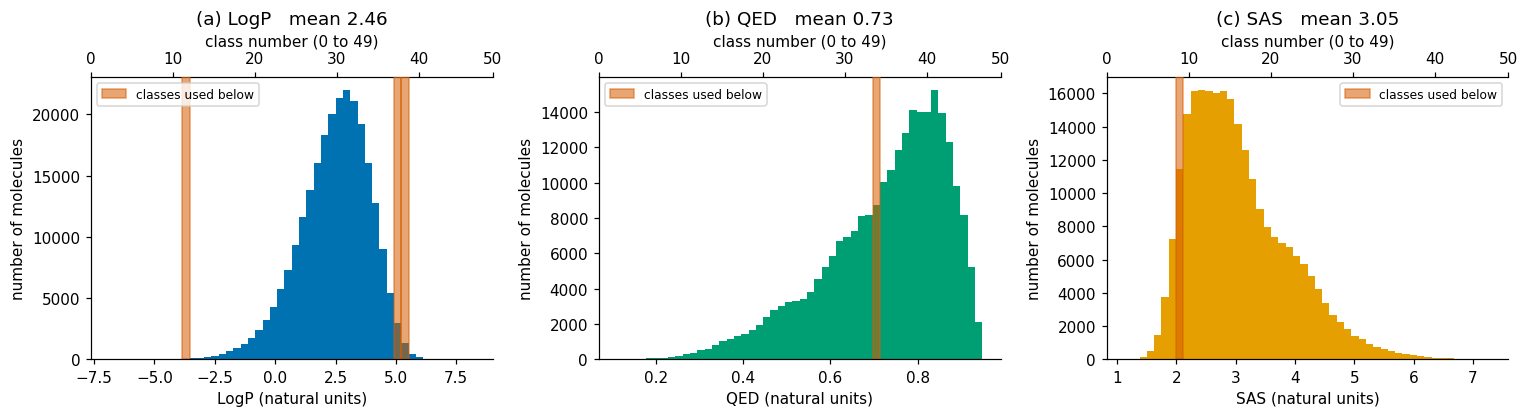

In [7]:
#@title Figure 2: the three properties and their classes { display-mode: "form" }
names = ["LogP", "QED", "SAS"]; edges_all = (class0, class1, class2)
marks = {0: (10, 39, 40), 1: (35,), 2: (7,)}                         # classes used in the examples below
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for j, a in enumerate(ax):
    e = edges_all[j]; step = e[1] - e[0]
    a.hist(properties[:, j], bins=50, color=[COLORS["blue"], COLORS["green"], COLORS["orange"]][j])
    for n_, k in enumerate(marks[j]):
        a.axvspan(e[k], e[k] + step, color=COLORS["red"], alpha=0.55, label="classes used below" if n_ == 0 else None)
    sec = a.secondary_xaxis("top", functions=(lambda v, e=e: np.interp(v, e, np.arange(50)), lambda k, e=e: np.interp(k, np.arange(50), e)))
    sec.set_xlabel("class number (0 to 49)")
    a.set(xlabel=f"{names[j]} (natural units)", ylabel="number of molecules", title=f"({'abc'[j]}) {names[j]}   mean {properties[:, j].mean():.2f}")
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Figure 2.** Distribution of LogP, QED and SAS over the 250,000 molecules (bottom axis: natural units; top axis: class number). Each property has its own shape, and the classes at the **edges** of the ranges contain very few molecules: the requested LogP classes 10 and 40, for instance, sit in the tails.

**Do the property values in the file agree with RDKit?** Later we will *measure* the properties of generated molecules with RDKit, so that "requested" and "achieved" values must be on the same scale. Before relying on that, let's check it: we recompute LogP (Crippen) and QED with RDKit for 1000 random ZINC molecules and compare them with the values stored in the file.

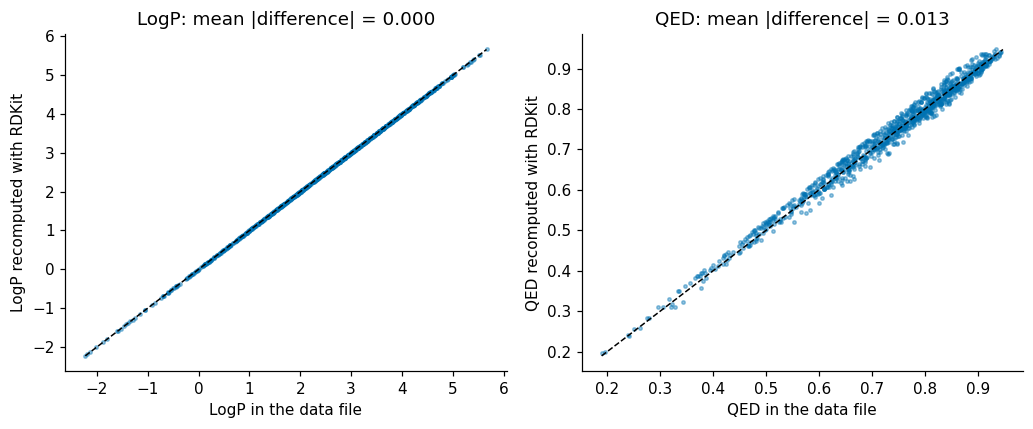

In [8]:
#@title Figure 3: properties in the file versus RDKit { display-mode: "form" }
chk = np.random.default_rng(SEED).choice(len(csv), size=1000, replace=False)
rd = np.array([[Crippen.MolLogP(m), QED.qed(m)] for m in (Chem.MolFromSmiles(csv.smiles.values[i].strip()) for i in chk)])
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
for j, (name, col) in enumerate((("LogP", "logP"), ("QED", "qed"))):
    x, y = csv[col].values[chk], rd[:, j]
    ax[j].scatter(x, y, s=5, alpha=0.4, color=COLORS["blue"])
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]; ax[j].plot(lim, lim, "k--", lw=1)
    ax[j].set(xlabel=f"{name} in the data file", ylabel=f"{name} recomputed with RDKit",
              title=f"{name}: mean |difference| = {np.mean(np.abs(x - y)):.3f}")
plt.tight_layout(); plt.show()

**Figure 3.** If the points lie on the diagonal, the values stored in the file are the ones RDKit computes, and "requested class" and "RDKit-measured value" can be compared directly. Systematic offsets or scatter would warn us that part of any later disagreement is a property of the *labels*, not of the model. (The synthetic-accessibility score SAS needs an additional RDKit contributed module, so we do not recompute it here.)

### 3.3 Tokenising the SMILES strings
The SMILES strings are processed exactly as in the companion VAE tutorial: a start marker `!` and an end marker `?` are added, every character is converted to a **token** by a dictionary (in order of first appearance, `'!'` is 0 and `'C'` is 1), all strings are **padded** to the same length with a padding token (36) that the model masks, and the data are split into 90 % for training (the first part of the file) and 10 % for testing. The only new step is the last one: **the three condition tokens are appended at the end of every row**.

In [9]:
# The csv stores a trailing newline after each SMILES string: strip it.
# (Nothing below modifies `csv` in place, so this cell can safely be re-run.)
raw_smiles = [s.strip() for s in csv.smiles.values]

# Add start-of-sequence character '!' and end-of-sequence character '?' and split into characters.
data = [['!'] + list(s) + ['?'] for s in raw_smiles]

# Make the conversion and inverse conversion dictionaries
smiledict = {}
label= 0
invdict = {}
for smile in data:
  for char in smile:
    if char not in smiledict:
      smiledict[char] = label
      invdict[label] = char
      label += 1

pad_index = len(smiledict) # This is the token for the pad
invdict[pad_index] = ' ' # Make the padding an empty character

maxlength = max(len(seq) for seq in data) # Longest SMILES sequence in the data
minlength = min(len(seq) for seq in data) # Shortest SMILES sequence in the data
print('The maximum length among the data set is '+str(maxlength))
print('The minimum length among the data set is '+str(minlength))
print('Number of distinct characters:', len(smiledict), '| padding token:', pad_index)

# The pre-trained model was built for exactly this data set: 36 characters, padding token 36, length 111.
if (len(smiledict), maxlength) != (36, 111):
  print('WARNING: the pre-trained model expects 36 distinct characters and a maximum length of 111; '
        'this csv differs, so the pre-trained model will not work with it.')

maxlength = maxlength + 4 # Allowing more space in case needed (total length = padded SMILES + 3 category tokens)

def char2ind(seq,trgdict = smiledict): # This translate a character to an index
  return([trgdict[char] for char in seq])

def ind2seq(seq):
  return(''.join(invdict[int(t)] for t in seq))

def pad(seq,maxlength): # Pad a token list IN PLACE to a given length with the padding token
  seq.extend([pad_index] * (maxlength - len(seq)))

testsize = math.ceil(len(data)/10) # Here we use 9/10 of the dataset for training

n_cat = categories.shape[1] # number of condition tokens (3)
smiles_len = maxlength - n_cat # every SMILES is padded to this length, then the 3 labels are appended

train_data = [char2ind(seq) for seq in data[:-testsize]] # Change all characters to index
test_data  = [char2ind(seq) for seq in data[-testsize:]]
for seq in train_data + test_data:
  pad(seq, smiles_len)

train_categories = categories[:-testsize]
test_categories = categories[-testsize:]

batch_size = 256

batch = [] # List of training batches, each of shape (batch_size, maxlength)
for i in range(0,len(train_data)-batch_size,batch_size): # (the last incomplete batch is dropped)
  seq = torch.tensor(train_data[i:i+batch_size]).long()
  cats = torch.LongTensor(train_categories[i:i+batch_size])
  batch.append(torch.cat((seq, cats),dim = 1)) # Concatenating the categories at the end of each (padded) string

# The test data as a single batch
batch_test = [torch.cat((torch.LongTensor(test_data), torch.LongTensor(test_categories)),dim = 1)]
print(len(batch), 'training batches of', tuple(batch[0].shape), '|', len(test_data), 'test molecules')

The maximum length among the data set is 111
The minimum length among the data set is 11
Number of distinct characters: 36 | padding token: 36
876 training batches of (256, 115) | 24946 test molecules


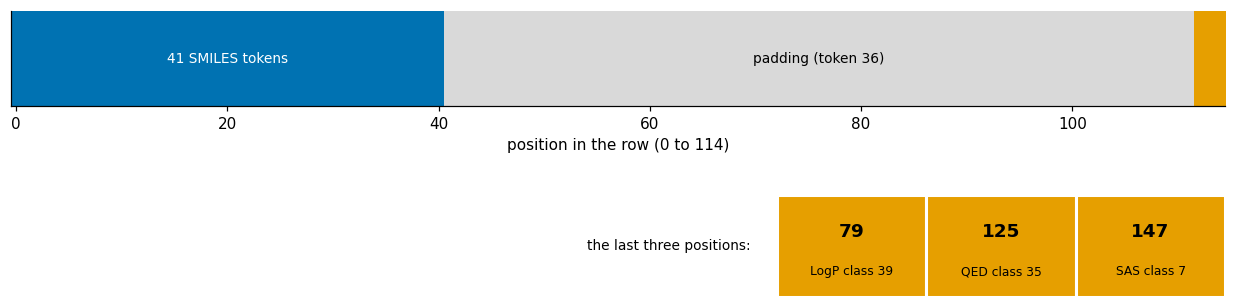

In [10]:
#@title Figure 4: anatomy of one input row { display-mode: "form" }
from matplotlib.colors import ListedColormap
row = batch[0][0].numpy()
kind = np.zeros(len(row), dtype=int); kind[row == pad_index] = 1; kind[-n_cat:] = 2     # 0: SMILES, 1: padding, 2: condition
n_smiles = int((row[:-n_cat] != pad_index).sum())

fig = plt.figure(figsize=(12, 3.1))
ax = fig.add_axes([0.04, 0.62, 0.92, 0.28])                                           # the whole row as a coloured strip
ax.imshow(kind[None, :], aspect="auto", cmap=ListedColormap([COLORS["blue"], "#d9d9d9", COLORS["orange"]]), vmin=0, vmax=2)
ax.set_yticks([]); ax.set_xlabel(f"position in the row (0 to {len(row) - 1})")
ax.text((n_smiles - 1) / 2, 0, f"{n_smiles} SMILES tokens", ha="center", va="center", color="white", fontsize=9)
ax.text((n_smiles + len(row) - n_cat - 1) / 2, 0, f"padding (token {pad_index})", ha="center", va="center", fontsize=9)

ax2 = fig.add_axes([0.62, 0.06, 0.34, 0.30])                                          # zoom on the last three positions
labels_ = ("LogP class", "QED class", "SAS class")
for i, p in enumerate(range(len(row) - n_cat, len(row))):
    ax2.add_patch(plt.Rectangle((i, 0), 1, 1, fc=COLORS["orange"], ec="white", lw=2))
    ax2.text(i + 0.5, 0.64, str(int(row[p])), ha="center", va="center", fontsize=12, weight="bold")
    ax2.text(i + 0.5, 0.25, f"{labels_[i]} {int(row[p]) - (40, 90, 140)[i]}", ha="center", va="center", fontsize=8)
ax2.set_xlim(0, n_cat); ax2.set_ylim(0, 1); ax2.axis("off")
fig.text(0.60, 0.21, "the last three positions:", ha="right", va="center", fontsize=9)
plt.show()

**Figure 4.** One row of the first training batch. The SMILES tokens (blue) come first, followed by padding (grey) up to a fixed length, and finally the three condition tokens (orange): here 79 (LogP class 39), 125 (QED class 35) and 147 (SAS class 7). The numbers are printed below. Each training batch is a tensor of 256 such rows.

In [11]:
print(batch[0][0])

tensor([  0,   1,   1,   2,   1,   3,   2,   1,   3,   4,   5,   4,   4,   4,
          6,   7,   4,   4,   2,   1,   1,   2,   8,   9,   3,  10,   4,  11,
          4,   4,   4,   4,   4,  11,  12,   3,   4,   6,   4,   5,  13,  36,
         36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,
         36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,
         36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,
         36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,
         36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,  36,
         79, 125, 147])


## 4. The model

### 4.1 Recap: Transformer and MMD autoencoder
The model is built from the same pieces as the unconditional VAE; the companion tutorial explains them in detail:

* a **Transformer encoder** and **decoder** (6 layers each, 4 attention heads, embedding size 128). Attention lets every position of the string look at every other position, which suits a language with long-range rules such as ring closures and branches; *masks* hide the padding, and in the decoder also all later positions (a character may only depend on the characters before it); the decoder also attends to the encoder output by *cross-attention*;
* an **autoencoder bottleneck**: the encoder output is compressed to a **latent vector** $z$ of $10\times128=1280$ numbers;
* the **MMD penalty**, which pulls the distribution of the latent vectors of real molecules toward the standard normal distribution $N(0,I)$, so that after training random draws from $N(0,I)$ are valid inputs to the decoder;
* **noise** (standard deviation 1) added to $z$ during training, so that the decoder learns to cope with perturbed latent vectors.

### 4.2 What is new: the condition
Two small changes make the model conditional:

1. **The encoder also returns the embeddings of the three condition tokens.** The condition tokens are part of the input row, so the encoder's attention layers see them. In addition, the encoder returns their *raw token embeddings* (taken straight from the embedding table, before positional information and attention): a $3\times128$ array $c$, flattened to $384$ numbers.
2. **The decoder input is $[z\;|\;c]$.** In the sequence-to-sequence model the (noised) latent vector is concatenated with $c$, giving $1280+384=1664$ numbers, which one linear layer maps to the $10\times128$ "memory" that the decoder attends to.

At generation time we skip the encoder: $z$ is drawn from $N(0,I)$, and $c$ is the embedding of the condition tokens that **we choose**.

> **A point to think about.** Because the encoder also sees the condition tokens, the latent vector $z$ *could* carry information about the properties, and then the decoder would have less reason to pay attention to $c$. Whether it does, is an empirical question; we test it in Section 6.2 with a simple regression.

### 4.3 Architecture and code map

| Component | Setting |
|---|---|
| input row | 112 SMILES positions (111 used at most) + 3 condition tokens = 115 tokens |
| embedding table | 190 entries: SMILES tokens 0–36, unused 37–39, condition tokens 40–189; embedding size 128 |
| encoder / decoder | 6 layers each, 4 attention heads, feed-forward width 256, dropout 0.1 |
| latent vector $z$ | encoder output $115\times128=14{,}720$ numbers → linear layer → **1280 numbers** |
| condition $c$ | embeddings of the 3 condition tokens, $3\times128=384$ numbers |
| decoder input | $[z+\text{noise}\;|\;c]$: 1664 numbers → linear layer → **10 "memory" vectors** of size 128 |
| trainable parameters | 23,046,693 (printed below) |

Where to look in the code: `Encoder` (note the extra output `c`), `Seq2Seq.forward` (encode → latent vector → add noise → concatenate with $c$ → decode), and `translate_sentence` (greedy generation, one character at a time, with an optional condition `C`).

In [12]:
class Encoder(nn.Module):
    def __init__(self,
                 input_dim,
                 hid_dim,
                 n_layers,
                 n_heads,
                 pf_dim,
                 dropout,
                 device,
                 num_categories = 3,
                 max_length = 120):
        super().__init__()

        self.device = device

        self.tok_embedding = nn.Embedding(input_dim, hid_dim)
        self.pos_embedding = nn.Embedding(max_length, hid_dim)
        self.n_cat = num_categories
        self.layers = nn.ModuleList([EncoderLayer(hid_dim,
                                                  n_heads,
                                                  pf_dim,
                                                  dropout,
                                                  device)
                                     for _ in range(n_layers)])

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, src, src_mask):

        #src = [batch size, src len]
        #src_mask = [batch size, 1, 1, src len]

        batch_size = src.shape[0]
        src_len = src.shape[1]

        pos = torch.arange(0, src_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)

        #pos = [batch size, src len]


        src_emb =self.tok_embedding(src)
        c = src_emb[:,-self.n_cat:,:] # Here we extract the embedding of the 3 categories

        src = self.dropout(src_emb* self.scale + self.pos_embedding(pos))

        #src = [batch size, src len, hid dim]

        for layer in self.layers:
            src = layer(src, src_mask)

        #src = [batch size, src len, hid dim]

        return src,c

class EncoderLayer(nn.Module):
    def __init__(self,
                 hid_dim,
                 n_heads,
                 pf_dim,
                 dropout,
                 device):
        super().__init__()

        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim,
                                                                     pf_dim,
                                                                     dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_mask):

        #src = [batch size, src len, hid dim]
        #src_mask = [batch size, 1, 1, src len]

        #self attention
        _src, _ = self.self_attention(src, src, src, src_mask)

        #dropout, residual connection and layer norm
        src = self.self_attn_layer_norm(src + self.dropout(_src))

        #src = [batch size, src len, hid dim]

        #positionwise feedforward
        _src = self.positionwise_feedforward(src)

        #dropout, residual and layer norm
        src = self.ff_layer_norm(src + self.dropout(_src))

        #src = [batch size, src len, hid dim]

        return src

class MultiHeadAttentionLayer(nn.Module):
    def __init__(self, hid_dim, n_heads, dropout, device):
        super().__init__()

        assert hid_dim % n_heads == 0

        self.hid_dim = hid_dim
        self.n_heads = n_heads
        self.head_dim = hid_dim // n_heads

        self.fc_q = nn.Linear(hid_dim, hid_dim)
        self.fc_k = nn.Linear(hid_dim, hid_dim)
        self.fc_v = nn.Linear(hid_dim, hid_dim)

        self.fc_o = nn.Linear(hid_dim, hid_dim)

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([self.head_dim])).to(device)

    def forward(self, query, key, value, mask = None):

        batch_size = query.shape[0]

        #query = [batch size, query len, hid dim]
        #key = [batch size, key len, hid dim]
        #value = [batch size, value len, hid dim]

        Q = self.fc_q(query)
        K = self.fc_k(key)
        V = self.fc_v(value)

        #Q = [batch size, query len, hid dim]
        #K = [batch size, key len, hid dim]
        #V = [batch size, value len, hid dim]

        Q = Q.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        K = K.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        V = V.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)

        #Q = [batch size, n heads, query len, head dim]
        #K = [batch size, n heads, key len, head dim]
        #V = [batch size, n heads, value len, head dim]

        energy = torch.matmul(Q, K.permute(0, 1, 3, 2)) / self.scale

        #energy = [batch size, n heads, query len, key len]

        if mask is not None:
            energy = energy.masked_fill(mask == 0, -1e10)

        attention = torch.softmax(energy, dim = -1)

        #attention = [batch size, n heads, query len, key len]

        x = torch.matmul(self.dropout(attention), V)

        #x = [batch size, n heads, query len, head dim]

        x = x.permute(0, 2, 1, 3).contiguous()

        #x = [batch size, query len, n heads, head dim]

        x = x.view(batch_size, -1, self.hid_dim)

        #x = [batch size, query len, hid dim]

        x = self.fc_o(x)

        #x = [batch size, query len, hid dim]

        return x, attention

class PositionwiseFeedforwardLayer(nn.Module):
    def __init__(self, hid_dim, pf_dim, dropout):
        super().__init__()

        self.fc_1 = nn.Linear(hid_dim, pf_dim)
        self.fc_2 = nn.Linear(pf_dim, hid_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        #x = [batch size, seq len, hid dim]

        x = self.dropout(torch.relu(self.fc_1(x)))

        #x = [batch size, seq len, pf dim]

        x = self.fc_2(x)

        #x = [batch size, seq len, hid dim]

        return x

class Decoder(nn.Module):
    def __init__(self,
                 output_dim,
                 hid_dim,
                 n_layers,
                 n_heads,
                 pf_dim,
                 dropout,
                 device,
                 max_length = 120):
        super().__init__()

        self.device = device
        self.hid_dim = hid_dim
        self.max_length = max_length
        self.tok_embedding = nn.Embedding(output_dim, hid_dim)
        self.pos_embedding = nn.Embedding(max_length, hid_dim)

        self.layers = nn.ModuleList([DecoderLayer(hid_dim,
                                                  n_heads,
                                                  pf_dim,
                                                  dropout,
                                                  device)
                                     for _ in range(n_layers)])

        self.fc_out = nn.Linear(hid_dim, output_dim)

        self.dropout = nn.Dropout(dropout)

        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, trg, enc_src, trg_mask, src_mask):

        #trg = [batch size, trg len]
        #enc_src = [batch size, src len, hid dim]
        #trg_mask = [batch size, 1, trg len, trg len]
        #src_mask = [batch size, 1, 1, src len]

        batch_size = trg.shape[0]
        trg_len = trg.shape[1]

        pos = torch.arange(0, trg_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)

        #pos = [batch size, trg len]

        trg = self.dropout((self.tok_embedding(trg) * self.scale) + self.pos_embedding(pos))

        #trg = [batch size, trg len, hid dim]

        for layer in self.layers:
            trg, attention = layer(trg, enc_src, trg_mask, src_mask)

        #trg = [batch size, trg len, hid dim]
        #attention = [batch size, n heads, trg len, src len]

        output = self.fc_out(trg)

        #output = [batch size, trg len, output dim]

        return output, attention

class DecoderLayer(nn.Module):
    def __init__(self,
                 hid_dim,
                 n_heads,
                 pf_dim,
                 dropout,
                 device):
        super().__init__()

        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.enc_attn_layer_norm = nn.LayerNorm(hid_dim)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.encoder_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim,
                                                                     pf_dim,
                                                                     dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, trg, enc_src, trg_mask, src_mask):

        #trg = [batch size, trg len, hid dim]
        #enc_src = [batch size, src len, hid dim]
        #trg_mask = [batch size, 1, trg len, trg len]
        #src_mask = [batch size, 1, 1, src len]

        #self attention
        _trg, _ = self.self_attention(trg, trg, trg, trg_mask)

        #dropout, residual connection and layer norm
        trg = self.self_attn_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]

        #encoder attention
        _trg, attention = self.encoder_attention(trg, enc_src, enc_src, src_mask)

        #dropout, residual connection and layer norm
        trg = self.enc_attn_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]

        #positionwise feedforward
        _trg = self.positionwise_feedforward(trg)

        #dropout, residual and layer norm
        trg = self.ff_layer_norm(trg + self.dropout(_trg))

        #trg = [batch size, trg len, hid dim]
        #attention = [batch size, n heads, trg len, src len]

        return trg, attention

class Seq2Seq(nn.Module):
    def __init__(self,
                 encoder,
                 decoder,
                 src_pad_idx,
                 trg_pad_idx,
                 device,
                 bottle_len
                 ):
        super().__init__()
        self.bottle_len = bottle_len
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.trg_pad_idx = trg_pad_idx
        self.device = device

        self.tanh = nn.Tanh()

        self.latent = nn.Linear(in_features = maxlength*self.decoder.hid_dim, out_features = bottle_len*self.decoder.hid_dim, bias = True)

        self.inverse = nn.Linear(in_features = (bottle_len+self.encoder.n_cat)*self.decoder.hid_dim, out_features = bottle_len*self.decoder.hid_dim)


        self.relu = nn.ReLU()
    def make_src_mask(self, src):

        #src = [batch size, src len]

        src_mask = (src != self.src_pad_idx).unsqueeze(1).unsqueeze(2)

        #src_mask = [batch size, 1, 1, src len]

        return src_mask

    def make_trg_mask(self, trg):

        #trg = [batch size, trg len]

        trg_pad_mask = (trg != self.trg_pad_idx).unsqueeze(1).unsqueeze(2)

        #trg_pad_mask = [batch size, 1, 1, trg len]

        trg_len = trg.shape[1]

        trg_sub_mask = torch.tril(torch.ones((trg_len, trg_len), device = self.device)).bool()

        #trg_sub_mask = [trg len, trg len]

        trg_mask = trg_pad_mask & trg_sub_mask

        #trg_mask = [batch size, 1, trg len, trg len]

        return trg_mask

    def forward(self, src, trg):

        #src = [batch size, src len]
        #trg = [batch size, trg len]

        src_mask = self.make_src_mask(src)
        trg_mask = self.make_trg_mask(trg)

        #src_mask = [batch size, 1, 1, src len]
        #trg_mask = [batch size, 1, trg len, trg len]

        enc_src,c = self.encoder(src, src_mask)
        #enc_src = [batch size, src len, hid dim]

        latent = self.latent(enc_src.reshape(-1,maxlength*self.decoder.hid_dim)) # Here the latent vector is generated
        noise_latent = latent + 1*torch.randn_like(latent) # We add noise during training

        noise_latent = torch.cat((noise_latent,c.view(-1,self.encoder.n_cat*self.decoder.hid_dim)),dim = 1).to(device) # This noised latent is concatenated with the 3 conditions

        enc_src = self.inverse(noise_latent).reshape(-1,self.decoder.hid_dim,self.bottle_len)
        enc_src = enc_src.permute(0, 2, 1)




        output, attention = self.decoder(trg, enc_src, trg_mask, src_mask = None)

        #output = [batch size, trg len, output dim]
        #attention = [batch size, n heads, trg len, src len]

        return output, attention, latent


torch.manual_seed(8)

INPUT_DIM = 40  + 150 # adding the number of categories
OUTPUT_DIM = len(invdict)
HID_DIM =  128
ENC_LAYERS = 6
DEC_LAYERS = 6
ENC_HEADS = 4 # HID_DIM must be integer divisible by head
DEC_HEADS = 4
ENC_PF_DIM = 2*HID_DIM # Encoder positional feedforward expansion dimension
DEC_PF_DIM = 2*HID_DIM # Decoder positional feedforward expansion dimension

ENC_DROPOUT = 0.1
DEC_DROPOUT = 0.1

bottle_len = 10

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

enc = Encoder(INPUT_DIM,
              HID_DIM,
              ENC_LAYERS,
              ENC_HEADS,
              ENC_PF_DIM,
              ENC_DROPOUT,
              device,
              max_length = 200
              )

dec = Decoder(OUTPUT_DIM,
              HID_DIM,
              DEC_LAYERS,
              DEC_HEADS,
              DEC_PF_DIM,
              DEC_DROPOUT,
              device,
              max_length = 200
              )


model = Seq2Seq(enc, dec, pad_index, pad_index, device, bottle_len = bottle_len).to(device)


optimizer = optim.Adam(model.parameters(),lr = 0.0005)
criterion = nn.CrossEntropyLoss(ignore_index = pad_index,reduction = 'mean')# Ignore the value that corresponds to padding

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters')



def translate_sentence(src, model, device, max_len = 120, randz = False, return_Z = False, C = None):
    # This function does the translation from a sources input to target
    model.eval()

    src_tensor = src.to(device).view(1,-1)

    src_mask = model.make_src_mask(src_tensor)

    with torch.no_grad():

        enc_src,c = model.encoder(src_tensor, src_mask)
        if(C is not None): # If we have a condition
          C = torch.LongTensor(C).view(-1,len(categories[0])).to(device) # (on the same device as the model)
          c = model.encoder.tok_embedding(C)

        z = model.latent(enc_src.reshape(-1,maxlength*model.decoder.hid_dim))

        if(randz == True):  # If we want to sample from the latent space P(Z,C)
          z = torch.randn_like(z)

        z = torch.cat((z,c.view(-1,model.encoder.n_cat*model.decoder.hid_dim)),dim = 1)# Concatenating the conditions

        enc_src = model.inverse(z).reshape(-1,model.decoder.hid_dim,model.bottle_len)


        enc_src = enc_src.permute(0, 2, 1)


    trg_indexes = [0] # 0 is the token for start

    for i in range(max_len):

        trg_tensor = torch.LongTensor(trg_indexes).unsqueeze(0).to(device)

        trg_mask = model.make_trg_mask(trg_tensor)

        with torch.no_grad():
            output, attention = model.decoder(trg_tensor, enc_src, trg_mask, src_mask = None)

        pred_token = output.argmax(2)[:,-1].item()

        trg_indexes.append(pred_token)

        if pred_token == smiledict['?']:
            break
    output = ''
    for i in trg_indexes:
      output += invdict[i]


    if(return_Z == True):
        return(z)
    return output[1:-1]

The model has 23,046,693 trainable parameters


## 5. Training and loading the model

The training objective is the same as in the VAE: cross-entropy (rebuild the SMILES string, ignoring padding) plus the MMD penalty, optimised with Adam, with **teacher forcing** (the decoder receives the true string shifted by one position and predicts the next character everywhere). Unlike the VAE tutorial, where the MMD weight had to be increased gradually, this model can be trained with a **single set of parameters**. Training is still time-consuming: the author reports about **50 minutes of GPU time for 10 epochs**, which gives results similar to those of the pre-trained model. We therefore do not train here by default; set `RUN_TRAINING` below if you want to explore, and the loss curves are plotted at the end of the section.

### 5.1 Loading the pre-trained model
A pickled model remembers the device it was saved on, so the next cell maps it to the device of your current runtime (GPU or CPU). Importantly, it also **creates a fresh optimiser for the loaded model**: the optimiser created in the previous section still points at the parameters of the discarded, untrained model. If you provided a `state_dict` file instead, the weights are loaded into the model built in Section 4 with `weights_only=True`.

In [13]:
#@title Load the pre-trained model { display-mode: "form" }
def relocate(m, device):
  """Move a (pickled) model to `device`.

  The classes above keep `device` and `scale` as plain attributes (not parameters/buffers), so
  `m.to(device)` alone does not update them; we do it by hand."""
  m.to(device)
  for sub in m.modules():
    if hasattr(sub, 'device'):
      sub.device = device
    if hasattr(sub, 'scale') and torch.is_tensor(sub.scale):
      sub.scale = sub.scale.to(device)
  return m

class _DeviceUnpickler(pickle.Unpickler):
  """Unpickle a whole model, mapping tensors saved on a GPU to the current device (works on CPU runtimes too)."""
  def find_class(self, module, name):
    if module == 'torch.storage' and name == '_load_from_bytes':
      return lambda b: torch.load(io.BytesIO(b), map_location=device, weights_only=False)
    return super().find_class(module, name)

if MODEL_PATH is None:
  print("No pre-trained model provided: keeping the randomly initialised model from the previous section.")
elif MODEL_PATH.endswith(".pt"):                       # weights only: the safe format
  model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
  model.eval()
  optimizer = optim.Adam(model.parameters(), lr = 0.0005)
  print(f'Loaded the state_dict {MODEL_PATH}: {count_parameters(model):,} trainable parameters, running on {device}')
else:                                                  # a pickled model (only load files that you trust!)
  with open(MODEL_PATH, 'rb') as f:
    model = _DeviceUnpickler(f).load()
  model = relocate(model, device)
  model.eval()
  # A new optimizer is needed: the old one still points at the parameters of the discarded model.
  optimizer = optim.Adam(model.parameters(), lr = 0.0005)
  print(f'Loaded {MODEL_PATH}: {count_parameters(model):,} trainable parameters, running on {device}')

Loaded CVAE_transformer_model.pckl: 23,046,693 trainable parameters, running on cuda


In [14]:
#@title (Optional) Export the weights as a state_dict { display-mode: "form" }
#@markdown Saves only the numbers (not the code), which is the safe, portable way to share a model.
export_state_dict = False #@param {type:"boolean"}
if export_state_dict:
  fname = "CVAE_transformer_state_dict.pt"
  torch.save(model.state_dict(), fname)
  digest = hashlib.sha256(open(fname, "rb").read()).hexdigest()
  print(f"saved {fname} ({os.path.getsize(fname)/1e6:.1f} MB)\nSHA-256: {digest}")
  print("model configuration: HID_DIM=%d, layers=%d/%d, heads=%d/%d, pf_dim=%d, bottle_len=%d, pad_index=%d, n_cat=%d" %
        (HID_DIM, ENC_LAYERS, DEC_LAYERS, ENC_HEADS, DEC_HEADS, ENC_PF_DIM, bottle_len, pad_index, n_cat))
  if IN_COLAB:
    from google.colab import files
    files.download(fname)

In [15]:
#@title Run (optional) training? { display-mode: "form" }
RUN_TRAINING = False #@param {type:"boolean"}
N_EPOCHS = 1 #@param {type:"integer"}
#@markdown One epoch takes roughly 5 minutes on a T4 GPU; about 10 epochs are needed from scratch. Leave off to evaluate the pre-trained model as it is.
if RUN_TRAINING and MODEL_PATH is None:
  print("NOTE: no pre-trained model was loaded; plan for about 10 epochs (roughly an hour of GPU time) to get a useful model.")

In [16]:
history = {'ce': [], 'mmd': []}   # losses recorded every 10 batches, for plotting

def K(x, y): # This computes the kernel between x and y
    x_size = x.shape[0]
    y_size = y.shape[0]
    dim = x.shape[1]
    tiled_x = x.view(x_size,1,dim).repeat(1, y_size,1)
    tiled_y = y.view(1,y_size,dim).repeat(x_size, 1,1)

    return torch.exp(-torch.mean((tiled_x - tiled_y)**2,dim=2)/(dim*0.0005)) # [batch_size, 1]


def mmd(x, y): # The MMD loss between x and y

    #return torch.mean(K(x, x)) + torch.mean(K(y, y)) - 2*torch.mean(K(x, y))
    return 4*(1 - torch.mean(K(x, y)))

def train(model, train_batch, optimizer, criterion, clip):

    model.train()

    for i in tqdm(range(len(train_batch))):

        data = train_batch[i]
        src = data.to(device) # SMILES tokens followed by the 3 condition tokens
        trg = data[:,:-len(categories[0])].to(device) # Target: the SMILES tokens only

        optimizer.zero_grad()

        outputs = model(src, trg[:,:-1]) # The second output is the attention
        output = outputs[0]
        latent = outputs[-1]

        output_dim = output.shape[-1]

        output = output.reshape(-1, output_dim)
        trg = trg[:,1:].reshape(-1)
        # The MMD loss compares the latent distribution to a standard normal distribution
        mmd_loss = mmd(latent, torch.randn(1000, bottle_len*HID_DIM, device=device))
        ce_loss = criterion(output, trg)
        loss = ce_loss + mmd_loss

        if(i%10 == 0):
          history['ce'].append(ce_loss.item()); history['mmd'].append(mmd_loss.item())
        if(i%100 == 0):
          print('Cross Entropy Loss:', history['ce'][-1])
          print('MMD LOSS:', history['mmd'][-1])

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)

        optimizer.step()

if RUN_TRAINING:
  for epoch in range(N_EPOCHS):
    print('Epoch:', epoch+1)
    train(model, batch[:], optimizer, criterion, 1)
    with torch.no_grad():
      name = translate_sentence(batch[0][0], model, device, max_len = 120)
      if(is_SMILE(name)):
        print(name) # Check if it reconstructs molecule at batch[0][0]
      name = translate_sentence(batch[0][0], model, device, max_len = 120, randz = True)
      if(is_SMILE(name)):
        print(name) # Give me a molecule that is similar to this molecule at batch[0][0]
else:
  print('Training skipped (RUN_TRAINING is off).')

Training skipped (RUN_TRAINING is off).


In [17]:
#@title Figure 5: training curves { display-mode: "form" }
if history['ce']:
  fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
  steps_rec = np.arange(len(history['ce'])) * 10
  ax[0].plot(steps_rec, history['ce'], color=COLORS["blue"]); ax[0].set(xlabel="training step", ylabel="cross-entropy", title="(a) Reconstruction loss")
  ax[1].plot(steps_rec, history['mmd'], color=COLORS["pink"]); ax[1].set(xlabel="training step", ylabel="MMD term", title="(b) MMD penalty")
  plt.tight_layout(); plt.show()
else:
  print("No training was run in this session (RUN_TRAINING is off), so there are no curves to show.")

No training was run in this session (RUN_TRAINING is off), so there are no curves to show.


## 6. Evaluation without conditions: latent space and sampling

Before testing the conditioning (Section 7), we check the basics: does the latent space match its prior $N(0,I)$, does the latent vector carry property information, and what do we get when we sample with a typical condition?

### 6.1 Helper functions
To run thousands of molecules through the model we need helpers that work on whole batches: `tokens_to_smiles` (tokens to string), `condition_embedding` and `latent_to_memory` (build the decoder input from $z$ and the condition tokens), `decode_memory` (greedy decoding of a batch), `group_generate` (sample molecules for a condition) and `group_translate` (reconstruct molecules). `condition(logp_class, qed_class, sas_class)` converts class numbers (0 to 49) into the three condition tokens, checking that each is in its own range, for example `condition(39, 35, 7)` gives `[79, 125, 147]`.

In [18]:
def tokens_to_smiles(tokens):
    # Convert a sequence of tokens into a SMILES string: stop at the end marker '?', drop the start marker '!'
    chars = []
    for t in tokens:
        c = invdict[int(t)]
        if c == '?':
            break
        chars.append(c)
    return ''.join(chars)[1:]

def condition_embedding(c, n = 1):
    # Embed the 3 condition tokens c (e.g. [79, 125, 147]) and repeat them n times -> [n, 3*hid_dim]
    c = torch.LongTensor(c).view(-1,len(categories[0])).to(model.encoder.tok_embedding.weight.device)
    c = model.encoder.tok_embedding(c).view(1,-1,model.decoder.hid_dim)
    return c.repeat(n,1,1).view(n, model.encoder.n_cat*model.decoder.hid_dim)

def latent_to_memory(z_c):
    # Turn [latent vector, condition embedding] vectors into the 'memory' that the decoder attends to
    enc_src = model.inverse(z_c).reshape(-1,model.decoder.hid_dim,model.bottle_len)
    return enc_src.permute(0, 2, 1)

@torch.no_grad()
def decode_memory(enc_src, max_len = 120):
    # Greedy autoregressive decoding of a whole batch of memories into SMILES strings
    n = enc_src.shape[0]
    trg_indexes = torch.full((n, 1), smiledict['!'], dtype = torch.long, device = enc_src.device) # start token
    for i in range(max_len):
        trg_mask = model.make_trg_mask(trg_indexes)
        output, attention = model.decoder(trg_indexes, enc_src, trg_mask, src_mask = None)
        pred_token = output.argmax(2)[:,-1].view(-1,1)
        trg_indexes = torch.cat((trg_indexes, pred_token), dim = 1)
    return [tokens_to_smiles(row) for row in trg_indexes]

def group_generate(number = 100, c = [79, 125, 147], device = device, max_len = 120, chunk = 500):
    # Generate 'number' of molecules randomly for the condition c (in chunks, to limit GPU memory use)
    model.eval()
    generated = []
    with torch.no_grad():
        for start in range(0, number, chunk):
            n = min(chunk, number - start)
            z = torch.randn(n, bottle_len*model.decoder.hid_dim, device = device) # random latent vectors
            z = torch.cat((z, condition_embedding(c, n)), dim = 1) # Concatenating the conditions
            generated += decode_memory(latent_to_memory(z), max_len)
    return generated

def group_translate(src, device = device, max_len = 120, chunk = 500):
    # Reconstruct a group of molecules (each with its own conditions, which are part of src)
    model.eval()
    reconstructed = []
    with torch.no_grad():
        for start in range(0, len(src), chunk):
            src_tensor = src[start:start+chunk].to(device)
            src_mask = model.make_src_mask(src_tensor)
            enc_src, c = model.encoder(src_tensor, src_mask)
            z = model.latent(enc_src.reshape(-1,maxlength*model.decoder.hid_dim))
            z = torch.cat((z, c.reshape(-1,model.encoder.n_cat*model.decoder.hid_dim)), dim = 1)
            reconstructed += decode_memory(latent_to_memory(z), max_len)
    return reconstructed

def generateZ(z, c = [79, 125, 147], device = device, max_len = 120):
    # Generate a molecule from a given latent representation z and condition c
    model.eval()
    z = z.to(device).view(1,-1)
    z = torch.cat((z, condition_embedding(c, 1)), dim = 1)
    with torch.no_grad():
        return decode_memory(latent_to_memory(z), max_len)[0]

def check_logp(smiles):
    # Crippen LogP computed by RDKit; None if the SMILES is not a valid molecule
    mol = Chem.MolFromSmiles(smiles)
    return Crippen.MolLogP(mol) if mol is not None else None

def condition(logp_class, qed_class, sas_class):
    # Class numbers (0..49 for each property) -> the three condition tokens.
    # LogP tokens are 40..89, QED tokens 90..139, SAS tokens 140..189 (the ORDER of the three matters).
    for name, k in (('logp_class', logp_class), ('qed_class', qed_class), ('sas_class', sas_class)):
        assert 0 <= k < 50, f'{name} must be between 0 and 49'
    return [40 + logp_class, 90 + qed_class, 140 + sas_class]

### 6.2 Does the latent space match the prior?
The MMD penalty is meant to make the latent vectors of real molecules look like draws from $N(0,I)$ in $d=1280$ dimensions. How do we check? A tempting test is to project the latent vectors on their first principal component and look at the histogram. **Be careful: this test is misleading when there are few molecules.** With $n$ points in $d$ dimensions, the first principal component of *perfect* $N(0,I)$ data has a standard deviation of about $1+\sqrt{d/n}$, not 1: for $n=256$ and $d=1280$ it is about 3.2. The fair comparison is with a **null reference**: random draws from $N(0,I)$ of the *same size* analysed in the *same way*. Figure 6 shows four views:

* (a) the first principal component of the encoded vectors versus the null;
* (b) the variance along the first 40 principal components, versus the null (a few dominant directions would mean that the latent vectors are spread very unevenly);
* (c) the length $\|z\|$ of each latent vector: for $N(0,I)$ it is concentrated near $\sqrt d\approx35.8$;
* (d) the standard deviation of each of the 1280 latent coordinates: the prior has 1.

We also compute the MMD penalty of the encoded vectors against the prior, next to a reference value obtained from two independent prior samples.

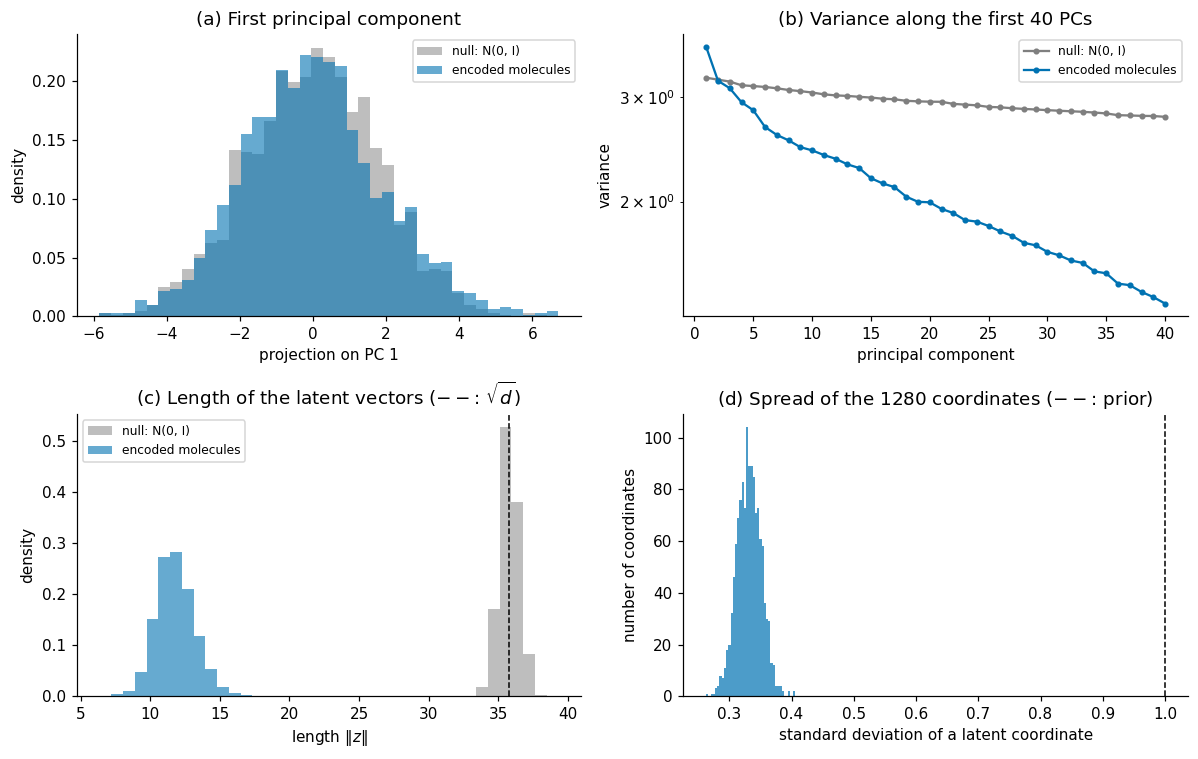

MMD term, encoded molecules vs prior : 3.282
MMD term, prior vs prior (reference) : 3.820
mean |z| = 11.8  (prior: 35.8);  mean coordinate std = 0.33  (prior: 1)


In [19]:
@torch.no_grad()
def encode_latents(src_batch, chunk=500):
    """Latent vectors z (n x 1280, numpy) of a batch of tokenised molecules (rows = SMILES tokens + 3 condition tokens)."""
    model.eval()
    out = []
    for start in range(0, len(src_batch), chunk):
        src = src_batch[start:start + chunk].to(device)
        enc, _ = model.encoder(src, model.make_src_mask(src))          # the encoder also returns the condition embeddings
        out.append(model.latent(enc.reshape(-1, maxlength * model.decoder.hid_dim)).cpu())
    return torch.cat(out).numpy()

n_lat = 2000
Z = encode_latents(batch_test[0][:n_lat])                        # latent vectors of 2000 test molecules
d_lat = Z.shape[1]
P = np.random.default_rng(SEED).normal(size=Z.shape)             # null reference: same size, drawn from N(0, I)

def pc_analysis(A):
    Ac = A - A.mean(axis=0, keepdims=True)
    U_, s_, Vt_ = np.linalg.svd(Ac, full_matrices=False)
    return Ac @ Vt_[0], s_ ** 2 / (len(A) - 1)                  # projection on PC 1, variance of every PC

pc1_z, var_z = pc_analysis(Z)
pc1_p, var_p = pc_analysis(P)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
bins = np.linspace(min(pc1_z.min(), pc1_p.min()), max(pc1_z.max(), pc1_p.max()), 40)
ax[0, 0].hist(pc1_p, bins, density=True, alpha=0.5, color=COLORS["gray"], label="null: N(0, I)")
ax[0, 0].hist(pc1_z, bins, density=True, alpha=0.6, color=COLORS["blue"], label="encoded molecules")
ax[0, 0].set(xlabel="projection on PC 1", ylabel="density", title="(a) First principal component"); ax[0, 0].legend(fontsize=8)
ax[0, 1].semilogy(np.arange(1, 41), var_p[:40], "o-", ms=3, color=COLORS["gray"], label="null: N(0, I)")
ax[0, 1].semilogy(np.arange(1, 41), var_z[:40], "o-", ms=3, color=COLORS["blue"], label="encoded molecules")
ax[0, 1].set(xlabel="principal component", ylabel="variance", title="(b) Variance along the first 40 PCs"); ax[0, 1].legend(fontsize=8)
nb_ = np.linspace(min(np.linalg.norm(Z, axis=1).min(), np.linalg.norm(P, axis=1).min()) - 1, max(np.linalg.norm(Z, axis=1).max(), np.linalg.norm(P, axis=1).max()) + 1, 40)
ax[1, 0].hist(np.linalg.norm(P, axis=1), nb_, density=True, alpha=0.5, color=COLORS["gray"], label="null: N(0, I)")
ax[1, 0].hist(np.linalg.norm(Z, axis=1), nb_, density=True, alpha=0.6, color=COLORS["blue"], label="encoded molecules")
ax[1, 0].axvline(np.sqrt(d_lat), color="k", ls="--", lw=1); ax[1, 0].set(xlabel=r"length $\|z\|$", ylabel="density", title=r"(c) Length of the latent vectors ($--$: $\sqrt{d}$)"); ax[1, 0].legend(fontsize=8)
ax[1, 1].hist(Z.std(axis=0), bins=40, color=COLORS["blue"], alpha=0.7)
ax[1, 1].axvline(1.0, color="k", ls="--", lw=1); ax[1, 1].set(xlabel="standard deviation of a latent coordinate", ylabel="number of coordinates", title="(d) Spread of the 1280 coordinates ($--$: prior)")
plt.tight_layout(); plt.show()

with torch.no_grad():
    a = torch.tensor(Z[:256], dtype=torch.float32, device=device)
    p1, p2 = torch.randn(256, d_lat, device=device), torch.randn(256, d_lat, device=device)
    print(f"MMD term, encoded molecules vs prior : {mmd(a, p1).item():.3f}")
    print(f"MMD term, prior vs prior (reference) : {mmd(p1, p2).item():.3f}")
print(f"mean |z| = {np.linalg.norm(Z, axis=1).mean():.1f}  (prior: {np.sqrt(d_lat):.1f});  mean coordinate std = {Z.std(axis=0).mean():.2f}  (prior: 1)")

**Figure 6.** Compare the encoded vectors (blue) with the null reference (grey). The closer the two are, in all four panels and in the MMD numbers printed below, the better the latent space matches its prior. A match does *not* guarantee valid molecules everywhere in the latent space; Section 6.3 measures that directly.

**Does the latent vector carry property information?** This question is specific to conditional models. If $z$ already encodes LogP, QED or SAS, the decoder can get the property from $z$ and may pay less attention to $c$, which weakens the control we want. A simple test: fit a (ridge) **linear regression** that predicts each property from $z$ on 1500 test molecules and score it with $R^2$ on the other 500. For comparison we repeat the fit with **shuffled labels**, which should give $R^2\approx0$ (or below).

In [20]:
props_test = csv.iloc[-testsize:].reset_index(drop=True).iloc[:n_lat]       # properties of the same 2000 test molecules
n_fit = 1500
rows = []
for name, col in (("LogP", "logP"), ("QED", "qed"), ("SAS", "SAS")):
    y = props_test[col].values
    reg = RidgeCV(alphas=[1, 10, 100, 1e3, 1e4]).fit(Z[:n_fit], y[:n_fit])
    r2 = r2_score(y[n_fit:], reg.predict(Z[n_fit:]))
    shuffled = np.random.default_rng(SEED).permutation(y[:n_fit])
    reg0 = RidgeCV(alphas=[1, 10, 100, 1e3, 1e4]).fit(Z[:n_fit], shuffled)
    rows.append((name, round(r2, 3), round(r2_score(y[n_fit:], reg0.predict(Z[n_fit:])), 3)))
display(pd.DataFrame(rows, columns=["property", "R2 from z (held-out)", "R2, shuffled labels (should be ~0)"]))

,property,R2 from z (held-out),"R2, shuffled labels (should be ~0)"
0,LogP,0.617,-0.013
1,QED,0.624,-0.006
2,SAS,0.742,-0.006


**Table 1.** How much of each property can a linear model read off the latent vector? $R^2$ near 0 means that $z$ carries little *linearly decodable* information about the property, so the condition has to come through $c$. $R^2$ near 1 means that $z$ knows the property, and the decoder may be able to ignore $c$. (A linear probe is only a lower bound for the information in $z$: a nonlinear model could find more.)

**A two-dimensional view.** Projecting the latent vectors on their first two principal components and colouring the points by LogP and QED shows whether the latent space is organised by these properties.

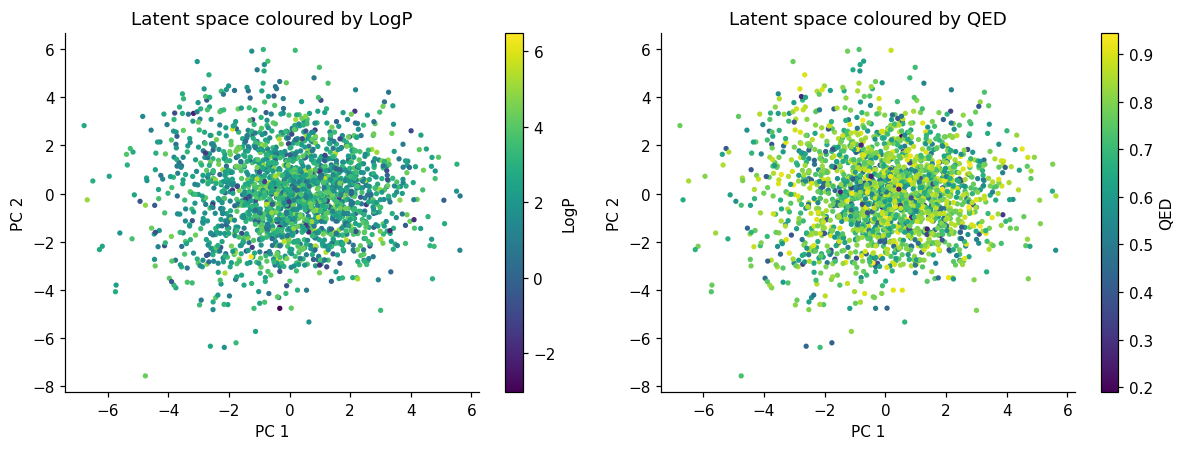

In [21]:
Z2 = PCA(n_components=2).fit_transform(Z)                          # 2-D projection of the 2000 latent vectors
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, col, label in zip(ax, ("logP", "qed"), ("LogP", "QED")):
    sc = a.scatter(Z2[:, 0], Z2[:, 1], c=props_test[col], s=6, cmap="viridis")
    fig.colorbar(sc, ax=a, label=label)
    a.set(xlabel="PC 1", ylabel="PC 2", title=f"Latent space coloured by {label}")
plt.tight_layout(); plt.show()

**Figure 7.** The same 2000 latent vectors coloured by LogP (left) and QED (right). Smooth gradients would mean that the dominant directions of the latent space are related to these properties; a random mix of colours means that they are not (consistent with a small $R^2$ in Table 1). A two-dimensional PCA captures only a small part of a 1280-dimensional space, so weak structure may be invisible here.

### 6.3 Sampling with a typical condition
We now sample random latent vectors and decode them, with the same condition for all: the **typical** classes `[79, 125, 147]` (LogP class 39, QED class 35, SAS class 7), which lie where the training data are abundant (Figure 2). We use the standard metrics of the field (see MOSES and GuacaMol in the References):

| Metric | Definition |
|---|---|
| **Parses as SMILES** | RDKit can read the string (grammar only). |
| **Chemically valid** | the string also passes RDKit's sanitisation (valence rules, aromaticity). **This is the validity that matters.** |
| **Repeated** | valid generated molecules that duplicate another generated molecule (complement of *uniqueness*). |
| **Novel** | distinct valid molecules that are not in the 250,000 ZINC molecules; both sides are converted to RDKit's **canonical SMILES** first. |
| **Exactly reconstructed** | test molecules that are decoded back to the identical string (each with its own condition tokens). |

First we canonicalise the ZINC molecules (about a minute and a half), then we draw 5000 random latent vectors and decode them. The random seed is fixed, so the numbers are reproducible on the same hardware.

In [22]:
def canonical(smiles):
  # RDKit's canonical SMILES (same molecule -> same string); None if the string is not a valid molecule
  m = Chem.MolFromSmiles(smiles)
  return Chem.MolToSmiles(m) if m is not None else None

zinc_canonical = set(filter(None, (canonical(s) for s in tqdm(raw_smiles, desc = 'canonicalising ZINC'))))
print(len(zinc_canonical), 'distinct ZINC molecules')

set_seed(SEED)                                   # reproducible random latent vectors
numbers = 5000
generated_smiles = group_generate(numbers, c = [79, 125, 147]) # a typical condition (abundant labels)

parse_ok = [s for s in generated_smiles if is_SMILE(s)]
valid = [s for s in generated_smiles if is_valid_molecule(s)]
distinct = sorted(set(canonical(s) for s in valid))
valid_unique_smiles = [s for s in distinct if s not in zinc_canonical] # new, valid, distinct molecules

# --- reconstruction of test molecules (each with its own conditions, which are part of the input row) ---
test_samples = 5000
testsmile = [tokens_to_smiles(batch_test[0][i]) for i in range(test_samples)]
reconstructed = group_translate(batch_test[0][:test_samples])
match = sum(testsmile[i] == reconstructed[i] for i in range(test_samples))
print(f'{numbers} molecules generated, {test_samples} test molecules reconstructed.')

canonicalising ZINC:   0%|          | 0/249455 [00:00<?, ?it/s]

249455 distinct ZINC molecules
5000 molecules generated, 5000 test molecules reconstructed.


In [23]:
def percent_with_ci(k, n):
    if n == 0:
        return float('nan'), float('nan')
    p = k / n
    return 100 * p, 100 * 1.96 * np.sqrt(p * (1 - p) / n)        # normal-approximation 95 % interval

rows = [("Parses as SMILES (grammar only)",        len(parse_ok),                         numbers),
        ("Chemically valid",                       len(valid),                            numbers),
        ("Repeated (among valid)",                 len(valid) - len(distinct),            len(valid)),
        ("Novel (among distinct valid)",           len(valid_unique_smiles),              len(distinct)),
        ("Exactly reconstructed (test molecules)", match,                                 test_samples)]
table = pd.DataFrame([(m, k, n, *percent_with_ci(k, n)) for m, k, n in rows],
                     columns=["Metric", "count", "out of", "percent", "95% CI (+/- points)"])
try:
    display(table.round(2).style.hide(axis="index"))
except Exception:
    display(table.round(2))

Metric,count,out of,percent,95% CI (+/- points)
Parses as SMILES (grammar only),4975,5000,99.500000,0.200000
Chemically valid,4882,5000,97.640000,0.420000
Repeated (among valid),21,4882,0.430000,0.180000
Novel (among distinct valid),4857,4861,99.920000,0.080000
Exactly reconstructed (test molecules),2660,5000,53.200000,1.380000


**Table 2.** Results for 5000 random samples (typical condition) and 5000 test molecules. The last column is the approximate 95 % margin of error from the finite number of samples. These are **single draws with a fixed seed**.

How to read the table:
* The gap between "parses" and "chemically valid" counts strings that look like SMILES but break chemistry rules (next cell).
* "Novel" is measured against 250,000 molecules, a tiny part of chemical space: it shows that the model does not simply copy its training set, not that the molecules are new to chemistry.
* Reconstruction accuracy and sampling quality pull in opposite directions (the more the latent space is forced onto the prior, the harder exact reconstruction becomes). In the runs that accompany these two tutorials, the conditional model gave more valid samples than the unconditional one (about 97 % against 80 %) but reconstructed fewer test molecules exactly (about 53 % against 69 %); this is consistent with that trade-off, although the two models were also trained differently.

### How do the generated strings fail?
RDKit tells us whether a string cannot be parsed at all, or parses but violates valence or aromaticity rules.

In [24]:
def failure_kind(s):
    if len(s) == 0:
        return "empty string"
    m = Chem.MolFromSmiles(s, sanitize=False)
    if m is None:
        return "syntax error (cannot be parsed)"
    try:
        Chem.SanitizeMol(m)
        return "valid"
    except Exception as e:
        return type(e).__name__                                   # e.g. AtomValenceException, KekulizeException

kinds = Counter(failure_kind(s) for s in generated_smiles)
meaning = {"valid": "chemically valid molecule",
           "syntax error (cannot be parsed)": "unbalanced brackets or unclosed rings, not a legal SMILES",
           "AtomValenceException": "an atom has an impossible valence (too many bonds)",
           "AtomKekulizeException": "an aromatic ring cannot be written with alternating bonds",
           "KekulizeException": "an aromatic ring cannot be written with alternating bonds",
           "empty string": "the decoder produced no characters"}
print(f"{'outcome':36s} {'count':>6s} {'percent':>8s}   meaning")
for kind, k in kinds.most_common():
    print(f"{kind:36s} {k:6d} {100 * k / numbers:7.2f}%   {meaning.get(kind, 'other sanitisation error')}")
print("\nExamples of strings that fail:")
shown_kinds = Counter()
for s in generated_smiles:
    kind = failure_kind(s)
    if kind != "valid" and shown_kinds[kind] < 2:
        shown_kinds[kind] += 1; print(f"  [{kind}] {s[:90]}")

outcome                               count  percent   meaning
valid                                  4882   97.64%   chemically valid molecule
KekulizeException                        93    1.86%   an aromatic ring cannot be written with alternating bonds
syntax error (cannot be parsed)          25    0.50%   unbalanced brackets or unclosed rings, not a legal SMILES

Examples of strings that fail:
  [KekulizeException] Cc1cccc2cc(C)c(=O)cc12NC(=O)Cc1ccc(Br)cc1
  [KekulizeException] CCc1nc(C)c(NC(=O)c2ccc(-c3ccco3)cc2)c1C
  [syntax error (cannot be parsed)] Cc1ccc(CNC(=O)c2ccc3c(c2)CC(=O)c2ccccc2)cc1
  [syntax error (cannot be parsed)] Cc1ccc(NC(=O)Nc2cccc3c(c2)Cc2cccs2)cc1


### A random sample of generated molecules
Twelve **randomly chosen** novel, valid molecules from the typical-condition run, labelled with their QED and logP (showing the first twelve of a sorted list would give a biased picture).

In [25]:
valid_unique_smiles = list(valid_unique_smiles)
if not valid_unique_smiles:
    print("No novel valid molecules were generated (is the pre-trained model loaded?).")
    ms, legends = [], []
else:
    pick = np.random.default_rng(SEED).choice(len(valid_unique_smiles), size=min(12, len(valid_unique_smiles)), replace=False)
    ms = [Chem.MolFromSmiles(valid_unique_smiles[i]) for i in pick]
    legends = [f"QED {QED.qed(m):.2f} | logP {Crippen.MolLogP(m):.1f}" for m in ms]
show_grid(ms, legends, ncols=4, cell=(300, 250)) if ms else None

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Figure 8.** Twelve randomly chosen novel generated molecules (interactive 3D views: drag to rotate, scroll to zoom; the 3D structures are plausible conformers generated with RDKit, not computed minima). A chemically *valid* structure is not necessarily **stable, synthesisable or useful**, and "not in this 250k data set" does not mean "never seen before"; real applications need further filtering and expert review.

## 7. Conditional generation

Now the main question: **if we ask for a property value, do we get it?**

### 7.1 Requesting a condition
A condition is three class numbers (LogP, QED, SAS), each between 0 and 49, converted by `condition(...)` into three tokens. To think in natural units we need the *range of values* that a class covers. The helper functions below convert in both directions and `describe_condition` prints a request in natural units; `measure` computes LogP and QED of generated molecules with RDKit, independently of the model.

In [26]:
def class_range(prop, k):
    """Natural-unit range (low, high) of class k (0..49) of property prop (0 = LogP, 1 = QED, 2 = SAS)."""
    edges = (class0, class1, class2)[prop]
    return edges[k], edges[k] + (edges[1] - edges[0])

def describe_condition(logp_class, qed_class, sas_class):
    parts = []
    for p, k in enumerate((logp_class, qed_class, sas_class)):
        lo, hi = class_range(p, k)
        parts.append(f"{('LogP', 'QED', 'SAS')[p]} in [{lo:.2f}, {hi:.2f}]")
    return ", ".join(parts)

def measure(smiles_list):
    """RDKit (LogP, QED) of the valid strings, as an array of shape (n, 2); invalid strings are skipped."""
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        if m is None:
            continue
        try:
            out.append((Crippen.MolLogP(m), QED.qed(m)))
        except Exception:
            pass
    return np.array(out).reshape(-1, 2)

CLASS_BASE = (40, 90, 140)                                       # token number of class 0 of each property
def typical_condition(prop, k):
    """A REALISTIC full condition for class k of property prop: the other two classes are the medians among
    the training molecules that are in class k (or in the nearest populated class, if class k is empty)."""
    cls = categories - np.array(CLASS_BASE)                      # class numbers (0..49) of every molecule
    populated = np.unique(cls[:, prop])
    k_used = k if k in populated else int(populated[np.argmin(np.abs(populated - k))])
    rows = cls[cls[:, prop] == k_used]
    cond = [int(np.median(rows[:, p])) for p in range(3)]
    cond[prop] = k
    return tuple(cond)

print("Class 39 / 35 / 7  ->", describe_condition(39, 35, 7), "  tokens", condition(39, 35, 7))
print("LogP class 10      ->", describe_condition(10, 10, 10))
print("LogP class 40      ->", describe_condition(40, 10, 10))
print("typical full condition for LogP class 10:", typical_condition(0, 10), "->", describe_condition(*typical_condition(0, 10)))
print("typical full condition for LogP class 40:", typical_condition(0, 40), "->", describe_condition(*typical_condition(0, 40)))

Class 39 / 35 / 7  -> LogP in [4.92, 5.23], QED in [0.70, 0.71], SAS in [1.99, 2.12]   tokens [79, 125, 147]
LogP class 10      -> LogP in [-3.85, -3.55], QED in [0.28, 0.30], SAS in [2.36, 2.49]
LogP class 40      -> LogP in [5.23, 5.53], QED in [0.28, 0.30], SAS in [2.36, 2.49]
typical full condition for LogP class 10: (10, 21, 31) -> LogP in [-3.85, -3.55], QED in [0.46, 0.48], SAS in [4.95, 5.07]
typical full condition for LogP class 40: (40, 22, 11) -> LogP in [5.23, 5.53], QED in [0.48, 0.50], SAS in [2.49, 2.61]


Notice the last two lines. The three properties are **correlated** in real molecules: a very hydrophilic molecule (LogP class 10) tends to have certain QED and SAS values. If we request LogP class 10 but leave QED and SAS at arbitrary classes (as the first version of this tutorial did: class 10 for both), we may be asking for a combination that **hardly exists in the training data**. The function `typical_condition` builds a realistic request instead: it takes the QED and SAS classes that are *typical* for the requested LogP class.

### 7.2 Editing a molecule: same latent vector, different property
Our first test is the cleanest one. Take a real molecule, **keep its latent vector $z$**, and decode it again with a *different* LogP class, leaving QED and SAS unchanged. If the condition works, the decoded molecule should stay structurally related to the original (same $z$) but its LogP should follow the requested class. We use a helper that decodes latent vectors together with their own condition tokens.

In [27]:
@torch.no_grad()
def decode_z_c(z, cond, max_len=120, chunk=500):
    """Decode latent vectors z (n x 1280) together with their own condition tokens cond (n x 3) into SMILES strings."""
    model.eval()
    out = []
    for s in range(0, len(z), chunk):
        zz = torch.as_tensor(z[s:s + chunk], dtype=torch.float32, device=device)
        cc = torch.as_tensor(cond[s:s + chunk], dtype=torch.long, device=device)
        emb = model.encoder.tok_embedding(cc).reshape(len(cc), -1)            # n x (3*128): the embedded conditions
        out += decode_memory(latent_to_memory(torch.cat((zz, emb), dim=1)), max_len)
    return out

_fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def tanimoto(m1, m2):
    return DataStructs.TanimotoSimilarity(_fpgen.GetFingerprint(m1), _fpgen.GetFingerprint(m2))

# one molecule, five different requested LogP classes
src0 = batch_test[0][:1]
z0 = encode_latents(src0)                                                    # latent vector of the first test molecule
cond0 = src0[:, -n_cat:].numpy()[0]                                          # its own condition tokens
smi0 = tokens_to_smiles(src0[0])
shifts_demo = (-15, -7, 0, 7, 15)
conds = np.array([[int(np.clip(cond0[0] + sh, 40, 89)), cond0[1], cond0[2]] for sh in shifts_demo])
decoded = decode_z_c(np.repeat(z0, len(conds), axis=0), conds)

ms, legends = [Chem.MolFromSmiles(smi0)], [f"original: LogP {Crippen.MolLogP(Chem.MolFromSmiles(smi0)):.2f}"]
for sh, s, cnd in zip(shifts_demo, decoded, conds):
    m = Chem.MolFromSmiles(s) if is_valid_molecule(s) else None
    lo, hi = class_range(0, int(cnd[0]) - 40)
    if m is None:
        ms.append(None); legends.append(f"request LogP ~{(lo + hi) / 2:.1f}: invalid SMILES")
    else:
        ms.append(m); legends.append(f"request ~{(lo + hi) / 2:.1f}: LogP {Crippen.MolLogP(m):.2f}, sim {tanimoto(m, ms[0]):.2f}")
show_grid(ms, legends, ncols=3, cell=(320, 260))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Figure 9.** The first test molecule (top left) and the molecules obtained by decoding **the same latent vector** with five different requested LogP classes (the requested LogP at the centre of the class, the LogP that RDKit computes for the decoded molecule, and the Tanimoto similarity to the original). If the condition works, the measured LogP should follow the request; the shift of 0 classes should reproduce the original (or a close relative: exact reconstruction is not guaranteed).

One molecule proves nothing, so we repeat the experiment for 300 test molecules and five shifts, and plot the **change** in LogP that RDKit measures against the change that we asked for.

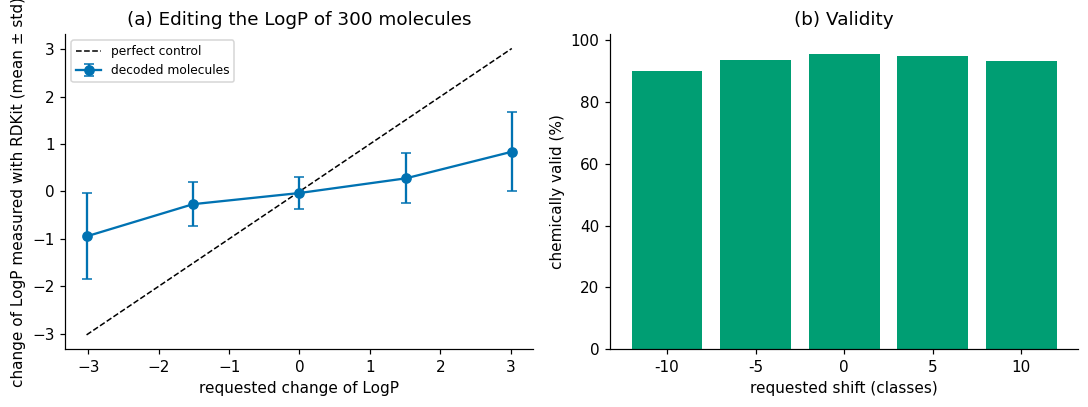

In [28]:
n_edit = 300
shifts = (-10, -5, 0, 5, 10)                                                 # requested shift in LogP classes
src_edit = batch_test[0][:n_edit]
z_edit = encode_latents(src_edit)
cond_orig = src_edit[:, -n_cat:].numpy().copy()
logp_orig = np.array([Crippen.MolLogP(Chem.MolFromSmiles(tokens_to_smiles(r))) for r in src_edit])
class_width = class0[1] - class0[0]

edit_rows = []
for sh in shifts:
    cond = cond_orig.copy(); cond[:, 0] = np.clip(cond[:, 0] + sh, 40, 89)
    dec = decode_z_c(z_edit, cond)
    asked = (cond[:, 0] - cond_orig[:, 0]) * class_width                    # requested change of LogP, in LogP units
    got = np.array([Crippen.MolLogP(Chem.MolFromSmiles(s)) - lo if is_valid_molecule(s) else np.nan for s, lo in zip(dec, logp_orig)])
    edit_rows.append((sh, asked.mean(), np.nanmean(got), np.nanstd(got), 100 * np.mean(~np.isnan(got))))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ask = [r[1] for r in edit_rows]
ax[0].errorbar(ask, [r[2] for r in edit_rows], yerr=[r[3] for r in edit_rows], fmt="o-", capsize=3, color=COLORS["blue"], label="decoded molecules")
ax[0].plot([min(ask), max(ask)], [min(ask), max(ask)], "k--", lw=1, label="perfect control")
ax[0].set(xlabel="requested change of LogP", ylabel="change of LogP measured with RDKit (mean ± std)", title="(a) Editing the LogP of 300 molecules"); ax[0].legend(fontsize=8)
ax[1].bar([str(r[0]) for r in edit_rows], [r[4] for r in edit_rows], color=COLORS["green"])
ax[1].set(xlabel="requested shift (classes)", ylabel="chemically valid (%)", title="(b) Validity", ylim=(0, 102))
plt.tight_layout(); plt.show()

**Figure 10.** (a) For each requested shift of the LogP class (width of one class: about 0.3 LogP units), the mean change of LogP that RDKit measures for the decoded molecules, with the standard deviation as error bars; the dashed line is perfect control. (b) The fraction of chemically valid decoded molecules. A curve that follows the dashed line means that the model understands the condition; a flat curve means that it ignores it; a curve that flattens at large shifts means that the model cannot follow requests far from the molecule's own LogP. Keep in mind that the edited molecule starts from its own latent vector, so the result also reflects how much property information $z$ carries (Table 1).

### 7.3 Sampling with a requested LogP: two examples
Next we sample at random latent vectors, as for generation from scratch, with a very **water soluble** request (LogP class 10, low LogP) and a very **octanol soluble** request (LogP class 40, high LogP). For each request we compare two ways of specifying the other properties: **(a)** QED and SAS fixed at class 10, as in the first version of this tutorial, and **(b)** QED and SAS **typical** for the requested LogP class. The function prints the requested ranges in natural units, then the properties that RDKit computes for the molecules that the model generated, and shows six of them.

In [29]:
def generate_and_report(cond, numbers=200, show=6, seed=SEED):
    tokens = condition(*cond)
    set_seed(seed)
    print("Requested:", describe_condition(*cond), "| tokens", tokens)
    generated = group_generate(numbers, c=tokens)
    valid = [s for s in generated if is_valid_molecule(s)]
    meas = measure(valid)
    print(f"  {len(valid)} of {numbers} generated molecules are chemically valid")
    if len(meas):
        print(f"  RDKit LogP: mean {meas[:, 0].mean():.2f}, std {meas[:, 0].std():.2f}   |   RDKit QED: mean {meas[:, 1].mean():.2f}, std {meas[:, 1].std():.2f}")
    shown = list(dict.fromkeys(valid))[:show]                        # first distinct valid molecules (random latent vectors, so unbiased)
    if shown:
        ms = [Chem.MolFromSmiles(s) for s in shown]
        show_grid(ms, [f"LogP {Crippen.MolLogP(m):.2f} | QED {QED.qed(m):.2f}" for m in ms], ncols=3, cell=(300, 240))
    else:
        print("  No chemically valid molecule was generated (is the pre-trained model loaded?).")
    return meas

print("=== very WATER SOLUBLE (LogP class 10), (a) QED and SAS fixed at class 10 ===")
ex_low_fixed = generate_and_report((10, 10, 10))

=== very WATER SOLUBLE (LogP class 10), (a) QED and SAS fixed at class 10 ===
Requested: LogP in [-3.85, -3.55], QED in [0.28, 0.30], SAS in [2.36, 2.49] | tokens [50, 100, 150]
  155 of 200 generated molecules are chemically valid
  RDKit LogP: mean -2.15, std 0.88   |   RDKit QED: mean 0.49, std 0.12


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [30]:
print("=== very WATER SOLUBLE (LogP class 10), (b) QED and SAS typical for this LogP class ===")
ex_low_typ = generate_and_report(typical_condition(0, 10))

=== very WATER SOLUBLE (LogP class 10), (b) QED and SAS typical for this LogP class ===
Requested: LogP in [-3.85, -3.55], QED in [0.46, 0.48], SAS in [4.95, 5.07] | tokens [50, 111, 171]
  184 of 200 generated molecules are chemically valid
  RDKit LogP: mean -2.53, std 0.98   |   RDKit QED: mean 0.52, std 0.09


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [31]:
print("=== very OCTANOL SOLUBLE (LogP class 40), (a) QED and SAS fixed at class 10 ===")
ex_high_fixed = generate_and_report((40, 10, 10))

=== very OCTANOL SOLUBLE (LogP class 40), (a) QED and SAS fixed at class 10 ===
Requested: LogP in [5.23, 5.53], QED in [0.28, 0.30], SAS in [2.36, 2.49] | tokens [80, 100, 150]
  155 of 200 generated molecules are chemically valid
  RDKit LogP: mean 5.04, std 0.72   |   RDKit QED: mean 0.45, std 0.14


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [32]:
print("=== very OCTANOL SOLUBLE (LogP class 40), (b) QED and SAS typical for this LogP class ===")
ex_high_typ = generate_and_report(typical_condition(0, 40))

=== very OCTANOL SOLUBLE (LogP class 40), (b) QED and SAS typical for this LogP class ===
Requested: LogP in [5.23, 5.53], QED in [0.48, 0.50], SAS in [2.49, 2.61] | tokens [80, 112, 151]
  171 of 200 generated molecules are chemically valid
  RDKit LogP: mean 4.95, std 0.59   |   RDKit QED: mean 0.58, std 0.12


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Figure 11.** Interactive 3D views of generated molecules for the four requests, labelled with the LogP and QED that RDKit computes for each one. Compare the printed **mean LogP** of the generated molecules with the **requested range**. For reference, an earlier run of this notebook (with QED and SAS fixed at class 10) gave a mean LogP of about $-2.0$ for the class-10 request (requested range from $-3.85$ to $-3.55$) and about $5.2$ for the class-40 request (requested from $5.23$ to $5.53$): the high-LogP request was honoured, the water-soluble one was not. Two explanations are plausible, and the next experiments can tell them apart: **(i)** the request is in a **sparse tail** of the training data (Figure 2), so the model has seen few molecules like that; **(ii)** the *combination* of LogP, QED and SAS was unrealistic. If (ii) is important, then request (b) should be closer to the target than request (a).

Finally, we compare the LogP distributions of the generated sets with the training data:

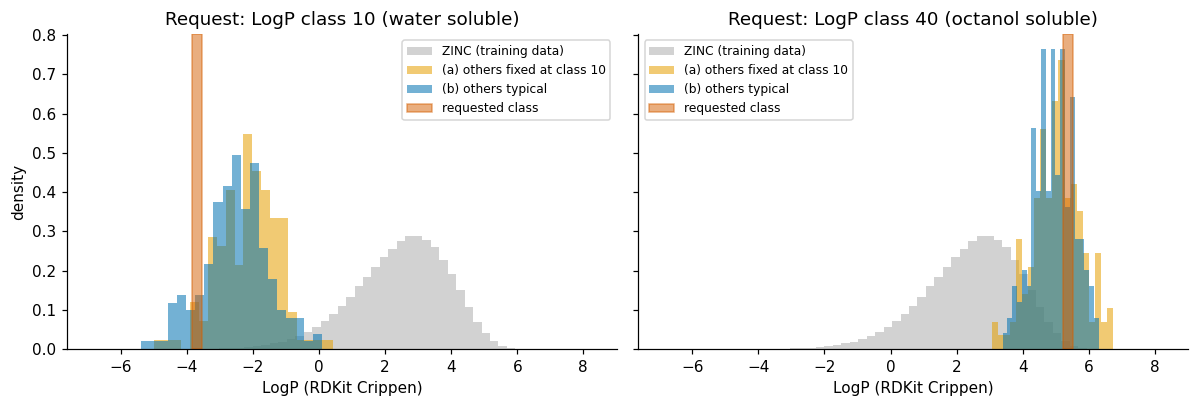

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
b = np.linspace(properties[:, 0].min(), properties[:, 0].max(), 60)
for a, (title, fixed, typ, k) in zip(ax, (("Request: LogP class 10 (water soluble)", ex_low_fixed, ex_low_typ, 10),
                                           ("Request: LogP class 40 (octanol soluble)", ex_high_fixed, ex_high_typ, 40))):
    a.hist(properties[:, 0], b, density=True, alpha=0.35, color=COLORS["gray"], label="ZINC (training data)")
    for meas, lab, col in ((fixed, "(a) others fixed at class 10", COLORS["orange"]), (typ, "(b) others typical", COLORS["blue"])):
        if len(meas):
            a.hist(meas[:, 0], bins=20, density=True, alpha=0.55, color=col, label=lab)
    lo, hi = class_range(0, k); a.axvspan(lo, hi, color=COLORS["red"], alpha=0.5, label="requested class")
    a.set(xlabel="LogP (RDKit Crippen)", title=title); a.legend(fontsize=8)
ax[0].set_ylabel("density")
plt.tight_layout(); plt.show()

**Figure 12.** LogP distributions of the generated molecules (orange: QED and SAS fixed at class 10; blue: typical QED and SAS) against the training data (grey) and the requested class (red band, only 0.3 LogP units wide). Even a well-controlled model produces a *spread* of LogP values around the request (this is a generative model, not a calculator); what we look for is a **peak that sits near the red band**. A peak far from the band means that the request was not honoured.

### 7.4 Does the control work in general? A systematic test
Two examples are anecdotes. A fair test scans **many requested LogP classes** and, for each one, generates a few hundred molecules and measures their LogP with RDKit. We do this with both ways of specifying the other properties, and we also record how many training molecules exist in each class. The cell generates 9 classes × 2 strategies × `n_per_class` molecules.

In [34]:
#@title Systematic scan { display-mode: "form" }
n_per_class = 300 #@param {type:"integer"}
scan_classes = tuple(range(5, 46, 5))

def scan_property(prop, classes, strategy, n=n_per_class, seed=SEED):
    """Generate n molecules per requested class of property `prop` and measure that property with RDKit."""
    rows = []
    for k in classes:
        if strategy == "typical":
            cond = typical_condition(prop, k)
        else:                                                            # "fixed": the other two classes stay at 10
            cond = [10, 10, 10]; cond[prop] = k
        set_seed(seed + k)
        smiles = group_generate(n, c=condition(*cond))
        valid = [s for s in smiles if is_valid_molecule(s)]
        meas = measure(valid)
        lo, hi = class_range(prop, k)
        rows.append(dict(requested_class=k, center=(lo + hi) / 2, n=n, n_valid=len(valid), cond=tuple(cond), measured=meas,
                         mean=meas[:, prop].mean() if len(meas) else np.nan, std=meas[:, prop].std() if len(meas) else np.nan))
    return rows

scan_logp = {s: scan_property(0, scan_classes, s) for s in ("fixed", "typical")}
summary = pd.DataFrame([dict(strategy=s, requested_class=r["requested_class"], requested_LogP=round(r["center"], 2),
                             mean_LogP=round(r["mean"], 2), std=round(r["std"], 2), valid_percent=round(100 * r["n_valid"] / r["n"], 1),
                             condition=r["cond"], training_molecules_in_class=int(((categories[:, 0] - 40) == r["requested_class"]).sum()))
                        for s, rows_ in scan_logp.items() for r in rows_])
display(summary)

,strategy,requested_class,requested_LogP,mean_LogP,std,valid_percent,condition,training_molecules_in_class
0,fixed,5,-5.21,-1.55,1.06,83.3,"(5, 10, 10)",4
1,fixed,10,-3.70,-1.94,1.01,83.7,"(10, 10, 10)",37
2,fixed,15,-2.19,-1.17,1.05,87.7,"(15, 10, 10)",406
3,fixed,20,-0.67,-0.09,0.93,87.0,"(20, 10, 10)",2380
4,fixed,25,0.84,1.47,0.93,90.0,"(25, 10, 10)",9368
5,fixed,30,2.35,2.63,0.85,86.7,"(30, 10, 10)",20044
6,fixed,35,3.86,3.82,0.77,84.0,"(35, 10, 10)",16067
7,fixed,40,5.38,5.14,0.74,78.7,"(40, 10, 10)",1328
8,fixed,45,6.89,5.75,0.76,79.3,"(45, 10, 10)",7
9,typical,5,-5.21,-2.27,1.04,92.0,"(5, 14, 35)",4


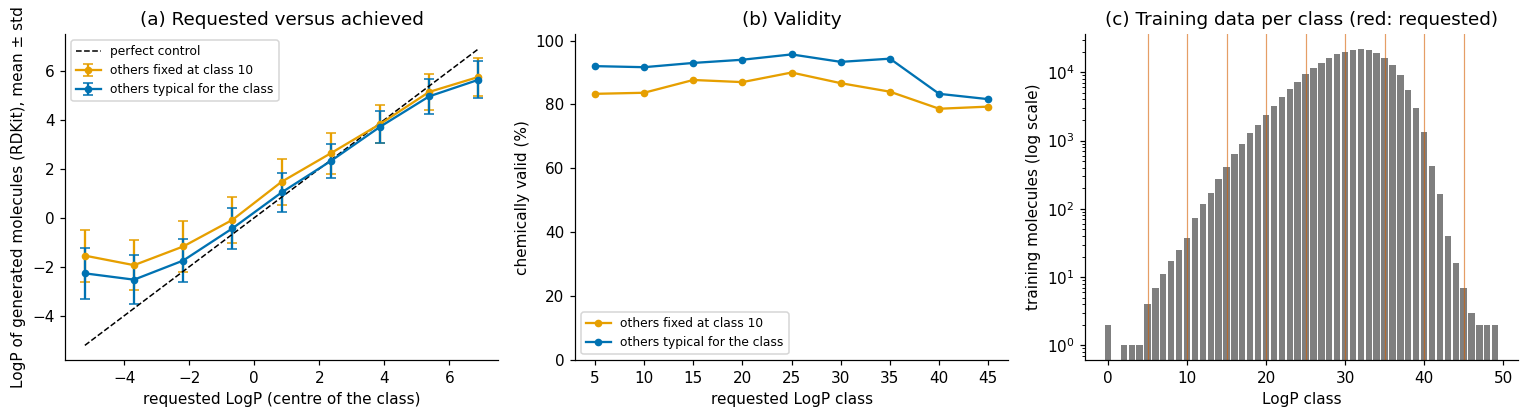

In [35]:
def plot_scan(prop, results):
    names = ("LogP", "QED", "SAS")
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
    colors = {"fixed": COLORS["orange"], "typical": COLORS["blue"]}
    labels = {"fixed": "others fixed at class 10", "typical": "others typical for the class"}
    for strat, rows_ in results.items():
        ax[0].errorbar([r["center"] for r in rows_], [r["mean"] for r in rows_], yerr=[r["std"] for r in rows_],
                       fmt="o-", ms=4, capsize=3, color=colors[strat], label=labels[strat])
        ax[1].plot([r["requested_class"] for r in rows_], [100 * r["n_valid"] / r["n"] for r in rows_], "o-", ms=4, color=colors[strat], label=labels[strat])
    first = next(iter(results.values()))
    c_lo, c_hi = min(r["center"] for r in first), max(r["center"] for r in first)
    ax[0].plot([c_lo, c_hi], [c_lo, c_hi], "k--", lw=1, label="perfect control")
    ax[0].set(xlabel=f"requested {names[prop]} (centre of the class)", ylabel=f"{names[prop]} of generated molecules (RDKit), mean ± std",
              title="(a) Requested versus achieved"); ax[0].legend(fontsize=8)
    ax[1].set(xlabel=f"requested {names[prop]} class", ylabel="chemically valid (%)", title="(b) Validity", ylim=(0, 102)); ax[1].legend(fontsize=8)
    support = np.bincount(categories[:, prop] - CLASS_BASE[prop], minlength=50)
    ax[2].bar(np.arange(50), support, color=COLORS["gray"]); ax[2].set_yscale("log")
    for r in first:
        ax[2].axvline(r["requested_class"], color=COLORS["red"], lw=0.8, alpha=0.6)
    ax[2].set(xlabel=f"{names[prop]} class", ylabel="training molecules (log scale)", title="(c) Training data per class (red: requested)")
    plt.tight_layout(); plt.show()

plot_scan(0, scan_logp)

**Figure 13.** (a) The LogP that RDKit measures for the generated molecules against the LogP requested, for the nine classes tested; the dashed diagonal is perfect control. (b) The percentage of chemically valid molecules per request. (c) The number of training molecules in each class (log scale): the red lines mark the requested classes.

**How to read it.**
* Where the achieved mean follows the diagonal, the model honours the request. Where it deviates, look at panel (c): deviations in classes with few training molecules point to **data sparsity**.
* If the blue curve (typical QED and SAS) lies closer to the diagonal than the orange one (fixed at class 10), then part of the earlier failure came from an **unrealistic combination** of requested properties, not from the model alone.
* Validity may also drop for sparse classes: the decoder has seen little of that region of molecule space.
* The error bars are the *spread* of the generated molecules, not the uncertainty of the mean; the uncertainty of each mean is smaller by a factor $\sqrt{n}$.

### 7.5 Controlling another property: QED
The same test works for the second property. QED is bounded (by 1), and its distribution is very different from that of LogP (Figure 2), so it is a useful second case. We scan QED classes, with the other two properties typical for the requested QED class, and measure QED with RDKit.

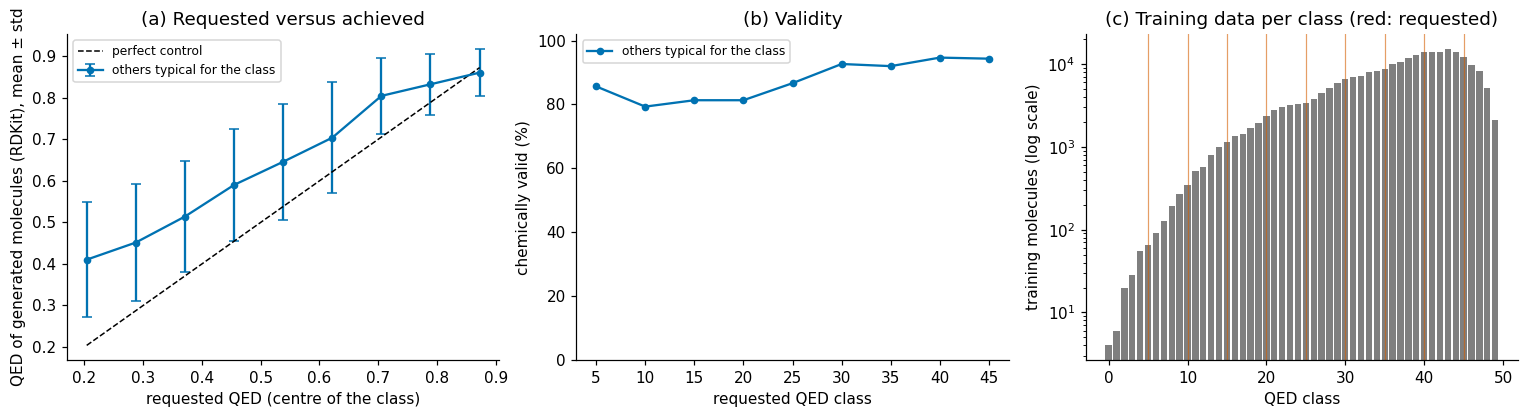

In [36]:
scan_qed = {"typical": scan_property(1, scan_classes, "typical")}
plot_scan(1, scan_qed)

**Figure 14.** The same test as in Figure 13 for QED (only the realistic "typical" request is shown). Compare how well the two properties are controlled, and relate the differences to the shapes of their distributions in Figure 2.

### 7.6 The joint picture
Properties are not independent: moving LogP moves other properties too. Using the molecules of the LogP scan with typical conditions, we plot the generated molecules in the LogP-QED plane over the density of the training data.

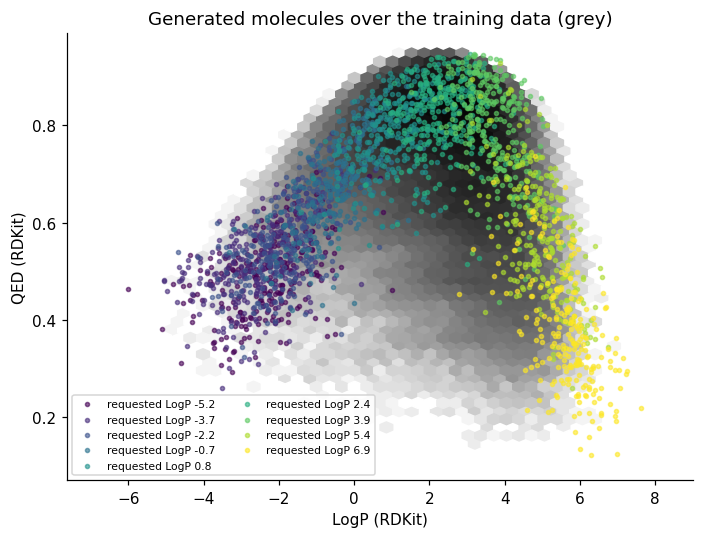

In [37]:
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(properties[:, 0], properties[:, 1], gridsize=45, cmap="Greys", bins="log", mincnt=1)
cmap = plt.get_cmap("viridis")
for i, r in enumerate(scan_logp["typical"]):
    if len(r["measured"]):
        ax.scatter(r["measured"][:, 0], r["measured"][:, 1], s=7, color=cmap(i / (len(scan_logp["typical"]) - 1)), alpha=0.6,
                   label=f"requested LogP {r['center']:.1f}")
ax.set(xlabel="LogP (RDKit)", ylabel="QED (RDKit)", title="Generated molecules over the training data (grey)")
ax.legend(fontsize=7, loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

**Figure 15.** Generated molecules (coloured by the requested LogP) in the LogP-QED plane, over the training data (grey density). Points that stay inside the grey cloud are realistic combinations of the two properties; points that wander outside it are properties that no training molecule has. The colour gradient from left to right shows how far the requested LogP moves the molecules.

### Summary of Section 7
Conditional generation works as far as the model has seen data: **editing** tests whether the condition is used at all, **sampling** tests whether it is honoured, and the **scans** show where it breaks. Always (i) measure the property independently, (ii) check how many training molecules exist near your request, and (iii) request realistic combinations of properties.

## 8. Check your understanding

1. Why can a standard VAE not give us molecules with a chosen LogP, while the TCVAE can?
2. How many numbers enter the linear layer that precedes the decoder in the conditional model, and where do they come from?
3. Why do the condition tokens start at 40, and why is the order (LogP, QED, SAS) important?
4. In Section 7.3, why can a *good* conditional model still produce a spread of LogP values around the requested one?
5. You request (LogP = $-3.7$, QED = 0.9) and the generated molecules have a very different LogP. Name two possible reasons.

<details><summary>Answers</summary>

1. A standard VAE models $p(x)$ only: it has no input through which a property could be specified. The TCVAE gives the decoder the condition $c$ explicitly, so it models $p(x\,|\,c)$.
2. 1664 numbers: the noised latent vector (1280) and the flattened embeddings of the three condition tokens (3 × 128 = 384).
3. The numbers 0 to 36 are taken by the SMILES characters and the padding token (37 to 39 are left unused); the 150 condition tokens follow. The order matters because the model identifies the property by the *position* of the token (the last three positions of the row), and tokens 40 to 89, 90 to 139 and 140 to 189 each belong to one property.
4. The model is generative: for a fixed condition there are many different molecules, with different properties, that are consistent with a *class* (an interval of values). The latent vector provides the variation. Perfect control would mean a spread comparable to the class width, which is not realistic.
5. (i) The requested LogP is in a sparse tail of the training data (Figure 2), so the model has little experience there; (ii) the *combination* (very hydrophilic and highly drug-like) may be rare or absent in the training data, so the model cannot satisfy both.
</details>

### Exercises
1. **Realistic requests.** Repeat Figure 13 with QED and SAS fixed at class 25 instead of 10. Does the "fixed" curve move toward or away from the "typical" one?
2. **Number of classes.** Re-discretise the properties into 20 or 100 classes (this changes the vocabulary: the model would have to be retrained). Predict how the width of the generated distribution would change.
3. **A third property.** Measure SAS with the RDKit Contrib `sascorer` module and scan the SAS classes as in Figure 14.
4. **Closing the loop.** Generate 1000 molecules for a request, measure their properties, and keep only those within a tolerance of the target (rejection sampling). How much does the hit rate improve, and what do you lose in diversity?
5. **Where does $z$ matter?** Repeat Figure 10 with $z$ replaced by a random draw from $N(0,I)$ for each molecule. Does the control change?
6. **Condition dropout.** Think about how you would modify the training so that the model also learns an unconditional mode (for example by randomly hiding the condition tokens), and what that would allow.

## 9. Troubleshooting

| Symptom | What to do |
|---|---|
| `FileNotFoundError` / the file picker did not appear | Re-run the "Provide the data files" cell; for Drive, check `drive_folder`. |
| Warning that the csv differs from what the pre-trained model expects | The pre-trained model only works with the original `250k_rndm_zinc_drugs_clean_3.csv` (36 characters, maximum length 111). |
| `AttributeError: Can't get attribute 'Seq2Seq' ...` while loading a `.pckl` | Run the model-definition cell (Section 4) **before** the loading cell: the pickle refers to those class names. |
| `RuntimeError` or key mismatch when loading a `.pt` file | The `state_dict` must come from this architecture (same sizes); run the model-definition cell first. |
| `AssertionError: ... must be between 0 and 49` | `condition(...)` takes class numbers 0 to 49, not tokens. |
| `CUDA out of memory` | Lower `chunk` in `group_generate` / `group_translate` / `decode_z_c`, or restart the runtime. |
| The systematic scan takes too long | Lower `n_per_class` (for example to 100). |
| Everything is extremely slow | You are on a CPU runtime: **Runtime → Change runtime type → GPU**, then run again from the top. |

## References
* A. Vaswani et al., *Attention is all you need*, Advances in Neural Information Processing Systems 30 (2017). arXiv:1706.03762
* D. P. Kingma, M. Welling, *Auto-encoding variational Bayes*, ICLR (2014). arXiv:1312.6114
* K. Sohn, H. Lee, X. Yan, *Learning structured output representation using deep conditional generative models*, Advances in Neural Information Processing Systems 28 (2015). (Conditional VAE.)
* J. Lim, S. Ryu, J. W. Kim, W. Y. Kim, *Molecular generative model based on conditional variational autoencoder for de novo molecular design*, J. Cheminform. **10**, 31 (2018).
* S. Kang, K. Cho, *Conditional molecular design with deep generative models*, J. Chem. Inf. Model. **59**, 43–52 (2019).
* S. Zhao, J. Song, S. Ermon, *InfoVAE: Information maximizing variational autoencoders* (2017). arXiv:1706.02262
* A. Gretton et al., *A kernel two-sample test*, J. Mach. Learn. Res. **13**, 723–773 (2012).
* S. R. Bowman et al., *Generating sentences from a continuous space*, CoNLL (2016). (Posterior collapse.)
* R. Gómez-Bombarelli et al., *Automatic chemical design using a data-driven continuous representation of molecules*, ACS Cent. Sci. **4**, 268–276 (2018).
* G. R. Bickerton, G. V. Paolini, J. Besnard, S. Muresan, A. L. Hopkins, *Quantifying the chemical beauty of drugs*, Nat. Chem. **4**, 90–98 (2012). (QED.)
* S. A. Wildman, G. M. Crippen, *Prediction of physicochemical parameters by atomic contributions*, J. Chem. Inf. Comput. Sci. **39**, 868–873 (1999). (Crippen LogP.)
* P. Ertl, A. Schuffenhauer, *Estimation of synthetic accessibility score of drug-like molecules*, J. Cheminform. **1**, 8 (2009). (SAS.)
* D. Weininger, *SMILES, a chemical language and information system*, J. Chem. Inf. Comput. Sci. **28**, 31–36 (1988).
* T. Sterling, J. J. Irwin, *ZINC 15 – ligand discovery for everyone*, J. Chem. Inf. Model. **55**, 2324–2337 (2015).
* D. Polykovskiy et al., *Molecular Sets (MOSES): a benchmarking platform for molecular generation models*, Front. Pharmacol. **11**, 565644 (2020).
* N. Brown et al., *GuacaMol: benchmarking models for de novo molecular design*, J. Chem. Inf. Model. **59**, 1096–1108 (2019).
* G. Landrum, *RDKit: open-source cheminformatics*, https://www.rdkit.org
* N. Rego, D. Koes, *3Dmol.js: molecular visualization with WebGL*, Bioinformatics **31**, 1322–1324 (2015). (The viewer behind py3Dmol.)